# Análise de Acromegalia - SIASUS

Análise de dados de APAC Medicamentos (AM) e Produção Ambulatorial (PA) do SIASUS para acromegalia.


In [1]:
# Função para gerar nome de arquivo com data atual
gerar_nome_arquivo <- function(indicador) {
  data_atual <- format(Sys.Date(), "%Y%m%d")
  return(paste0("../resultados/", data_atual, "_dados2024_", indicador, ".xlsx"))
}

# Função para gerar nome de arquivo PNG
gerar_nome_png <- function(indicador) {
  data_atual <- format(Sys.Date(), "%Y%m%d")
  return(paste0("../resultados/", data_atual, "_dados2024_", indicador, ".png"))
}

cat("Funções de formatação de data criadas!\n")
cat("Data atual:", format(Sys.Date(), "%Y%m%d"), "\n")



Funções de formatação de data criadas!
Data atual: 20260720 


## 1. Importação de Dados


In [2]:
# Carregar pacotes necessários
# install.packages("tidyverse")
# install.packages("lubridate")
# install.packages("readr")
# install.packages("stringr")
# install.packages("purrr")

library(tidyverse)
library(lubridate)
library(readr)
library(stringr)
library(purrr)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [3]:
# Carregar funções personalizadas
source("func/functions.R")


In [4]:
# Definir caminhos dos dados
caminho_dados <- "../data/raw"
caminho_saida <- "../data/processed"

# Criar diretório de saída se não existir
if (!dir.exists(caminho_saida)) {
  dir.create(caminho_saida, recursive = TRUE)
}

### Carregamento dos Dados


In [5]:
# Carregar dados de medicamentos (AM)
data_am <- list.files("../data/processed/medicamentos/", pattern = "\\.csv$", full.names = TRUE) %>%
  map_dfr(~ read_csv(.x, col_types = cols(.default = col_character())))

cat("Dados AM carregados:", nrow(data_am), "registros\n")
cat("Autorizações únicas AM:", n_distinct(data_am$AP_AUTORIZ), "\n")
cat("Autorizações AM com AP_AUTORIZ nulo:", sum(is.na(data_am$AP_AUTORIZ)), "\n")
cat("Pacientes únicos AM:", n_distinct(data_am$AP_CNSPCN), "\n")

Dados AM carregados: 84042 registros
Autorizações únicas AM: 39254 
Autorizações AM com AP_AUTORIZ nulo: 0 
Pacientes únicos AM: 4989 


In [6]:
# Carregar dados de produção ambulatorial (PA)
data_pa <- list.files("../data/processed/producao_ambulatorial/", pattern = "\\.csv$", full.names = TRUE) %>%
  map_dfr(~ read_csv(.x, col_types = cols(.default = col_character())))

cat("Dados PA carregados:", nrow(data_pa), "registros\n")
cat("Autorizações únicas PA:", n_distinct(data_pa$PA_AUTORIZ), "\n")
cat("Autorizações PA com PA_AUTORIZ nulo:", sum(is.na(data_pa$PA_AUTORIZ)), "\n")

Dados PA carregados: 97280 registros
Autorizações únicas PA: 30896 
Autorizações PA com PA_AUTORIZ nulo: 0 


## 2. Preparação dos Dados


In [7]:
# Transformar dados para padronização

## Dados de id da autorização (apenas se não for nulo)
data_am$AP_AUTORIZ <- ifelse(is.na(data_am$AP_AUTORIZ), NA, str_pad(as.character(data_am$AP_AUTORIZ), width = 15, pad = "0"))
data_pa$PA_AUTORIZ <- ifelse(is.na(data_pa$PA_AUTORIZ), NA, str_pad(as.character(data_pa$PA_AUTORIZ), width = 15, pad = "0"))

## Dados da unidade de saúde
data_am$AP_CODUNI <- str_pad(as.character(data_am$AP_CODUNI), width = 7, pad = "0")
data_pa$PA_CODUNI <- str_pad(as.character(data_pa$PA_CODUNI), width = 7, pad = "0")

## Dados do município
data_am$AP_MUNPCN <- str_pad(as.character(data_am$AP_MUNPCN), width = 7, pad = "0")
data_pa$PA_UFMUN <- str_pad(as.character(data_pa$PA_UFMUN), width = 7, pad = "0")

## Dados de data de competência (formato YYYY-MM-DD)
data_am$AP_CMP <- as.Date(paste0(data_am$AP_CMP, "01"), format = "%Y%m%d")
data_pa$PA_CMP <- as.Date(paste0(data_pa$PA_CMP, "01"), format = "%Y%m%d")

## Dados de data de movimentação (formato YYYY-MM-DD)
data_am$AP_MVM <- as.Date(paste0(data_am$AP_MVM, "01"), format = "%Y%m%d")
data_pa$PA_MVM <- as.Date(paste0(data_pa$PA_MVM, "01"), format = "%Y%m%d")

cat("Dados transformados com sucesso!\n")
cat("Formato de datas: YYYY-MM-DD\n")

Dados transformados com sucesso!
Formato de datas: YYYY-MM-DD


## 3. União dos Dados (AM + PA)


In [8]:
# Realizar o join entre AM e PA
dados_unificados <- data_am %>%
  left_join(data_pa, by = c(
    "AP_AUTORIZ" = "PA_AUTORIZ",
    "AP_CMP" = "PA_CMP",
    "AP_MVM" = "PA_MVM"
  ))

cat("Dados unificados:", nrow(dados_unificados), "registros\n")
cat("Autorizações únicas unificadas:", n_distinct(dados_unificados$AP_AUTORIZ), "\n")
cat("Pacientes únicos unificados:", n_distinct(dados_unificados$AP_CNSPCN), "\n")

Dados unificados: 103204 registros
Autorizações únicas unificadas: 39254 
Pacientes únicos unificados: 4989 


## 4. Filtro para o Ano de 2024


In [9]:
# Filtrar dados para o ano de 2024
dados_unificados <- dados_unificados %>%
  filter(AP_CMP >= as.Date("2024-01-01") & AP_CMP <= as.Date("2024-12-31"))

cat("Dados filtrados para 2024:", nrow(dados_unificados), "registros\n")
cat("Autorizações únicas em 2024:", n_distinct(dados_unificados$AP_AUTORIZ), "\n")
cat("Pacientes únicos em 2024:", n_distinct(dados_unificados$AP_CNSPCN), "\n")
cat("✅ Dataset unificado agora contém APENAS dados de 2024\n")

Dados filtrados para 2024: 47743 registros
Autorizações únicas em 2024: 19053 
Pacientes únicos em 2024: 4232 
✅ Dataset unificado agora contém APENAS dados de 2024


## 5. Resumo dos Dados Finais


In [10]:
# Resumo final dos dados
cat("=== RESUMO FINAL DOS DADOS UNIFICADOS ===\n\n")
cat("📊 DADOS UNIFICADOS (AM + PA) - 2024:\n")
cat("  • Total de registros:", nrow(dados_unificados), "\n")
cat("  • Total de autorizações únicas:", n_distinct(dados_unificados$AP_AUTORIZ), "\n")
cat("  • Total de pacientes únicos:", n_distinct(dados_unificados$AP_CNSPCN), "\n\n")

# Calcular autorizações sem paciente vinculado
autorizacoes_sem_paciente <- dados_unificados %>%
  filter(is.na(AP_CNSPCN)) %>%
  summarise(total = n_distinct(AP_AUTORIZ)) %>%
  pull(total)

cat("🔍 ANÁLISE DE COMPLETUDE:\n")
cat("  • Autorizações sem paciente vinculado:", autorizacoes_sem_paciente, "\n")
cat("  • Percentual de autorizações sem paciente:", round(autorizacoes_sem_paciente / n_distinct(dados_unificados$AP_AUTORIZ) * 100, 2), "%\n\n")

cat("📅 PERÍODO DOS DADOS:\n")
cat("  • Data mínima:", as.character(min(dados_unificados$AP_CMP, na.rm = TRUE)), "\n")
cat("  • Data máxima:", as.character(max(dados_unificados$AP_CMP, na.rm = TRUE)), "\n\n")

cat("✅ DADOS PRONTOS PARA ANÁLISE!\n")

=== RESUMO FINAL DOS DADOS UNIFICADOS ===

📊 DADOS UNIFICADOS (AM + PA) - 2024:
  • Total de registros: 47743 
  • Total de autorizações únicas: 19053 
  • Total de pacientes únicos: 4232 

🔍 ANÁLISE DE COMPLETUDE:
  • Autorizações sem paciente vinculado: 282 
  • Percentual de autorizações sem paciente: 1.48 %

📅 PERÍODO DOS DADOS:
  • Data mínima: 2024-01-01 
  • Data máxima: 2024-12-01 

✅ DADOS PRONTOS PARA ANÁLISE!


## 6. Análise Demográfica por Pacientes Únicos


In [11]:
# Preparar dados para análise demográfica
# Garantir que estamos trabalhando apenas com dados de 2024
dados_2024 <- dados_unificados %>%
  filter(AP_CMP >= as.Date("2024-01-01") & AP_CMP <= as.Date("2024-12-31"))

# Selecionar APENAS UMA autorização por paciente (AP_CNSPCN) em 2024
# Se houver empate na data, pegar apenas a primeira ocorrência
dados_pacientes_unicos <- dados_2024 %>%
  group_by(AP_CNSPCN) %>%
  arrange(desc(AP_CMP), desc(AP_AUTORIZ)) %>%  # Ordenar por data desc e autorização desc
  slice(1) %>%  # Pegar apenas a primeira linha (mais recente)
  ungroup()

cat("Dados de pacientes únicos de 2024 preparados:\n")
cat("  • Total de registros em 2024:", nrow(dados_2024), "\n")
cat("  • Total de pacientes únicos (AP_CNSPCN únicos):", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")
cat("  • Total de linhas em dados_pacientes_unicos:", nrow(dados_pacientes_unicos), "\n")
cat("  • Período das autorizações mais recentes:", 
    as.character(min(dados_pacientes_unicos$AP_CMP, na.rm = TRUE)), 
    "a", 
    as.character(max(dados_pacientes_unicos$AP_CMP, na.rm = TRUE)), "\n")

# Validação crítica: garantir que temos exatamente 4232 linhas
if(nrow(dados_pacientes_unicos) == 4232) {
  cat("✅ SUCESSO: dados_pacientes_unicos tem exatamente 4232 linhas!\n")
} else {
  cat("❌ ERRO: dados_pacientes_unicos tem", nrow(dados_pacientes_unicos), "linhas, deveria ter 4232!\n")
}

Dados de pacientes únicos de 2024 preparados:
  • Total de registros em 2024: 47743 
  • Total de pacientes únicos (AP_CNSPCN únicos): 4232 
  • Total de linhas em dados_pacientes_unicos: 4232 
  • Período das autorizações mais recentes: 2024-01-01 a 2024-12-01 
✅ SUCESSO: dados_pacientes_unicos tem exatamente 4232 linhas!


### 6.1 Análise por Sexo


In [12]:
# Calcular quantidade de pacientes únicos por sexo
# IMPORTANTE: Contar apenas AP_CNSPCN únicos, não registros
pacientes_por_sexo <- dados_pacientes_unicos %>%
  group_by(AP_SEXO) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),  # Contar AP_CNSPCN únicos por sexo
    .groups = "drop"
  ) %>%
  mutate(
    percentual = round(quantidade_pacientes / sum(quantidade_pacientes) * 100, 2)
  ) %>%
  arrange(desc(quantidade_pacientes))

# Adicionar linha de total
total_sexo <- pacientes_por_sexo %>%
  summarise(
    AP_SEXO = "TOTAL",
    quantidade_pacientes = sum(quantidade_pacientes),
    percentual = 100.0
  )

# Combinar dados com total
pacientes_por_sexo_com_total <- bind_rows(pacientes_por_sexo, total_sexo)

cat("Distribuição de pacientes únicos por sexo:\n")
print(pacientes_por_sexo_com_total)

# Validação: verificar se o total está correto
total_sexo_validacao <- sum(pacientes_por_sexo$quantidade_pacientes)
cat("\n✅ Validação - Total de pacientes únicos por sexo:", total_sexo_validacao, "\n")
cat("✅ Deve ser igual a:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")
cat("✅ Total correto de pacientes únicos em 2024:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")

Distribuição de pacientes únicos por sexo:
# A tibble: 3 × 3
  AP_SEXO quantidade_pacientes percentual
  <chr>                  <int>      <dbl>
1 F                       2601       61.5
2 M                       1631       38.5
3 TOTAL                   4232      100  

✅ Validação - Total de pacientes únicos por sexo: 4232 
✅ Deve ser igual a: 4232 
✅ Total correto de pacientes únicos em 2024: 4232 


In [13]:
# Exportar tabela de sexo para Excel
library(openxlsx)

# Criar diretório de resultados se não existir
if (!dir.exists("../resultados")) {
  dir.create("../resultados", recursive = TRUE)
}

# Exportar para Excel
write.xlsx(pacientes_por_sexo_com_total, 
           gerar_nome_arquivo("sexo"),
           sheetName = "Pacientes por Sexo",
           rowNames = FALSE)

cat("✅ Tabela de pacientes por sexo exportada para:", gerar_nome_arquivo("sexo"), "
")



✅ Tabela de pacientes por sexo exportada para: ../resultados/20260720_dados2024_sexo.xlsx 


### 6.2 Análise por Idade


In [14]:
# Calcular quantidade de pacientes únicos por idade
# IMPORTANTE: Contar apenas AP_CNSPCN únicos, não registros
# Primeiro, converter PA_IDADE para numérico
dados_pacientes_unicos$PA_IDADE <- as.numeric(dados_pacientes_unicos$PA_IDADE)

# Criar faixas etárias
pacientes_por_idade <- dados_pacientes_unicos %>%
  mutate(
    faixa_etaria = case_when(
      is.na(PA_IDADE) ~ "Idade desconhecida",
      PA_IDADE < 18 ~ "< 18 anos",
      PA_IDADE >= 18 & PA_IDADE <= 29 ~ "18 a 29 anos",
      PA_IDADE >= 30 & PA_IDADE <= 39 ~ "30 a 39 anos",
      PA_IDADE >= 40 & PA_IDADE <= 49 ~ "40 a 49 anos",
      PA_IDADE >= 50 & PA_IDADE <= 59 ~ "50 a 59 anos",
      PA_IDADE >= 60 & PA_IDADE <= 69 ~ "60 a 69 anos",
      PA_IDADE >= 70 & PA_IDADE <= 79 ~ "70 a 79 anos",
      PA_IDADE >= 80 ~ "80 anos ou mais",
      TRUE ~ "Idade inválida"
    )
  ) %>%
  mutate(faixa_etaria = factor(faixa_etaria, levels = c(
    "< 18 anos",
    "18 a 29 anos", 
    "30 a 39 anos",
    "40 a 49 anos",
    "50 a 59 anos",
    "60 a 69 anos",
    "70 a 79 anos",
    "80 anos ou mais",
    "Idade desconhecida",
    "Idade inválida"
  ))) %>%
  group_by(faixa_etaria) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),  # Contar AP_CNSPCN únicos por faixa etária
    .groups = "drop"
  ) %>%
  mutate(
    percentual = round(quantidade_pacientes / sum(quantidade_pacientes) * 100, 2)
  ) %>%
  arrange(faixa_etaria)

# Adicionar linha de total
total_idade <- pacientes_por_idade %>%
  summarise(
    faixa_etaria = "TOTAL",
    quantidade_pacientes = sum(quantidade_pacientes),
    percentual = 100.0
  )

# Combinar dados com total
pacientes_por_idade_com_total <- bind_rows(pacientes_por_idade, total_idade)

cat("Distribuição de pacientes únicos por faixa etária:\n")
print(pacientes_por_idade_com_total)

# Validação: verificar se o total está correto
total_idade_validacao <- sum(pacientes_por_idade$quantidade_pacientes)
cat("\n✅ Validação - Total de pacientes únicos por idade:", total_idade_validacao, "\n")
cat("✅ Deve ser igual a:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")
cat("✅ Total correto de pacientes únicos em 2024:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")

Distribuição de pacientes únicos por faixa etária:
# A tibble: 10 × 3
   faixa_etaria       quantidade_pacientes percentual
   <chr>                             <int>      <dbl>
 1 < 18 anos                            22       0.52
 2 18 a 29 anos                        160       3.78
 3 30 a 39 anos                        458      10.8 
 4 40 a 49 anos                        842      19.9 
 5 50 a 59 anos                        905      21.4 
 6 60 a 69 anos                        822      19.4 
 7 70 a 79 anos                        416       9.83
 8 80 anos ou mais                     139       3.28
 9 Idade desconhecida                  468      11.1 
10 TOTAL                              4232     100   

✅ Validação - Total de pacientes únicos por idade: 4232 
✅ Deve ser igual a: 4232 
✅ Total correto de pacientes únicos em 2024: 4232 


In [15]:
# Exportar tabela de idade para Excel
write.xlsx(pacientes_por_idade_com_total, 
           gerar_nome_arquivo("idade"),
           sheetName = "Pacientes por Idade",
           rowNames = FALSE)

cat("✅ Tabela de pacientes por idade exportada para:", gerar_nome_arquivo("idade"), "\n")

✅ Tabela de pacientes por idade exportada para: ../resultados/20260720_dados2024_idade.xlsx 


### 6.3 Pirâmide Etária


In [16]:
# Preparar dados para pirâmide etária
# Criar faixas etárias e contar pacientes únicos por sexo e idade
dados_piramide <- dados_pacientes_unicos %>%
  mutate(
    faixa_etaria = case_when(
      is.na(PA_IDADE) ~ "Idade desconhecida",
      PA_IDADE < 18 ~ "< 18 anos",
      PA_IDADE >= 18 & PA_IDADE <= 29 ~ "18-29 anos",
      PA_IDADE >= 30 & PA_IDADE <= 39 ~ "30-39 anos",
      PA_IDADE >= 40 & PA_IDADE <= 49 ~ "40-49 anos",
      PA_IDADE >= 50 & PA_IDADE <= 59 ~ "50-59 anos",
      PA_IDADE >= 60 & PA_IDADE <= 69 ~ "60-69 anos",
      PA_IDADE >= 70 & PA_IDADE <= 79 ~ "70-79 anos",
      PA_IDADE >= 80 ~ "80+ anos",
      TRUE ~ "Idade inválida"
    ),
    sexo_tratado = case_when(
      AP_SEXO %in% c("F", "M") ~ AP_SEXO,
      is.na(AP_SEXO) | AP_SEXO == "" ~ "Sexo desconhecido",
      TRUE ~ "Sexo inválido"
    )
  ) %>%
  mutate(
    faixa_etaria = factor(faixa_etaria, levels = c(
      "< 18 anos",
      "18-29 anos", 
      "30-39 anos",
      "40-49 anos",
      "50-59 anos",
      "60-69 anos",
      "70-79 anos",
      "80+ anos",
      "Idade desconhecida"
    )),
    sexo_tratado = factor(sexo_tratado, levels = c("F", "M", "Sexo desconhecido", "Sexo inválido"))
  ) %>%
  group_by(faixa_etaria, sexo_tratado) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),  # Contar AP_CNSPCN únicos
    .groups = "drop"
  ) %>%
  # Para pirâmide, usar valores negativos para homens
  mutate(
    qtd_plot = case_when(
      sexo_tratado == "M" ~ -quantidade_pacientes,
      sexo_tratado == "F" ~ quantidade_pacientes,
      TRUE ~ 0  # outros sexos não aparecem na pirâmide
    )
  )


✅ Pirâmide etária salva em: ../resultados/20260720_dados2024_piramide_etaria.png 


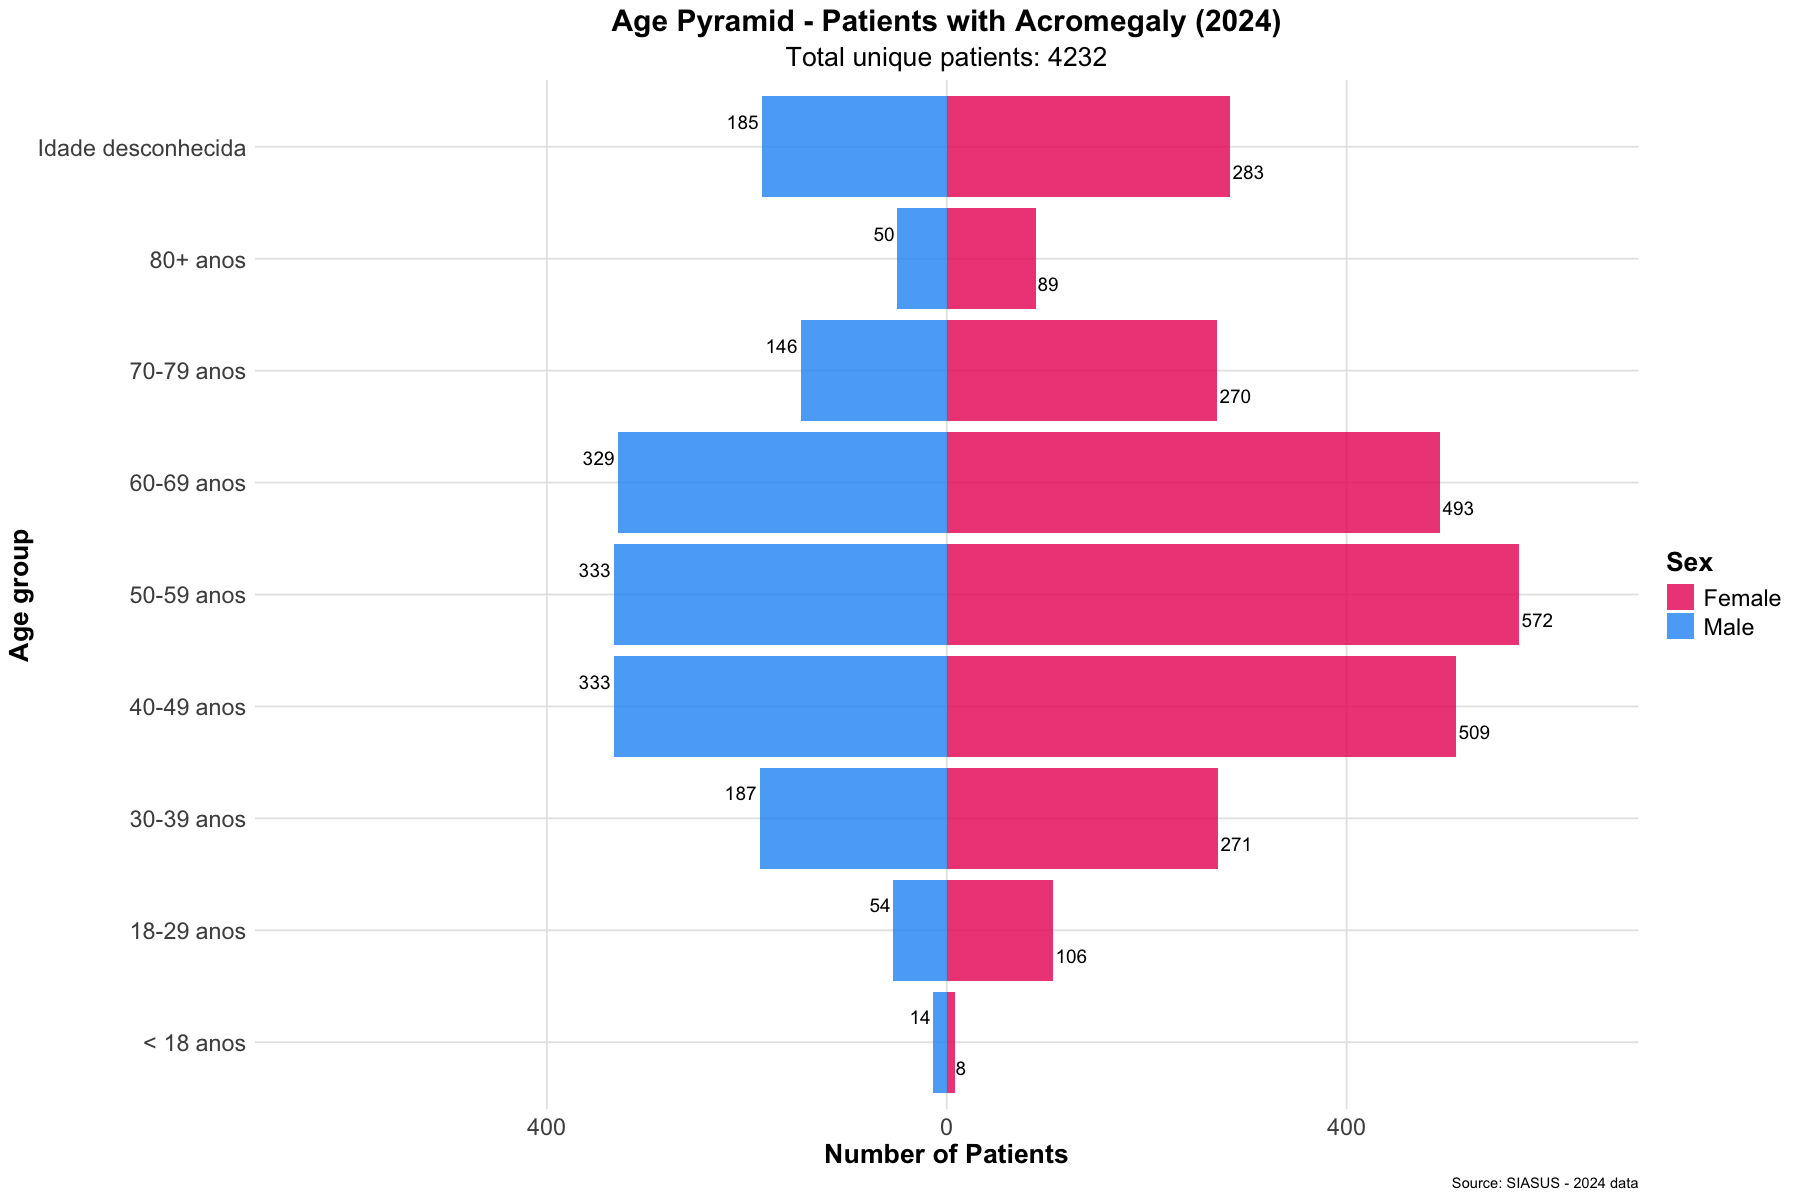

In [17]:
# Criar pirâmide etária
library(ggplot2)

# Filtrar apenas F e M para a pirâmide
dados_piramide_plot <- dados_piramide %>%
  filter(sexo_tratado %in% c("F", "M"))

# Calcular máximo para ajustar escala
max_valor <- max(abs(dados_piramide_plot$qtd_plot))

# Criar pirâmide etária
piramide_etaria <- ggplot(dados_piramide_plot, aes(x = faixa_etaria, y = qtd_plot, fill = sexo_tratado)) +
  geom_bar(stat = "identity", position = "identity", alpha = 0.8) +
  coord_flip() +
  scale_y_continuous(
    labels = function(x) abs(x),
    limits = c(-max_valor * 1.1, max_valor * 1.1)
  ) +
  scale_fill_manual(
    values = c("F" = "#E91E63", "M" = "#2196F3"),
    labels = c("F" = "Female", "M" = "Male")
  ) +
  labs(
    title = "Age Pyramid - Patients with Acromegaly (2024)",
    subtitle = paste("Total unique patients:", n_distinct(dados_pacientes_unicos$AP_CNSPCN)),
    x = "Age group",
    y = "Number of Patients",
    fill = "Sex",
    caption = "Source: SIASUS - 2024 data"
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(size = 18, face = "bold", hjust = 0.5),
    plot.subtitle = element_text(size = 16, hjust = 0.5),
    axis.text.x = element_text(size = 14),
    axis.text.y = element_text(size = 14),
    axis.title = element_text(size = 16, face = "bold"),
    legend.title = element_text(size = 16, face = "bold"),
    legend.text = element_text(size = 14),
    panel.grid.major = element_line(color = "grey90"),
    panel.grid.minor = element_blank()
  ) +
  geom_text(
    aes(label = ifelse(qtd_plot != 0, abs(qtd_plot), "")),
    position = position_dodge(width = 0.9),
    hjust = ifelse(dados_piramide_plot$qtd_plot >= 0, -0.1, 1.1),
    size = 4,
    color = "black"
  )

# Configurar tamanho da exibição no notebook
options(repr.plot.width = 15, repr.plot.height = 10)

# Exibir gráfico com tamanho maior
print(piramide_etaria)

# Salvar gráfico
ggsave(gerar_nome_png("piramide_etaria"), 
       plot = piramide_etaria, 
       width = 15, height = 10, dpi = 300)

cat("\n✅ Pirâmide etária salva em:", gerar_nome_png("piramide_etaria"), "\n")

In [18]:
# Resumo estatístico da pirâmide etária
cat("=== RESUMO DA PIRÂMIDE ETÁRIA ===\n\n")

# Estatísticas por sexo
resumo_sexo <- dados_piramide %>%
  filter(sexo_tratado %in% c("F", "M")) %>%
  group_by(sexo_tratado) %>%
  summarise(
    total_pacientes = sum(quantidade_pacientes),
    .groups = "drop"
  ) %>%
  mutate(
    percentual = round(total_pacientes / sum(total_pacientes) * 100, 1)
  )

# Adicionar linha de total
total_resumo_sexo <- resumo_sexo %>%
  summarise(
    sexo_tratado = "TOTAL",
    total_pacientes = sum(total_pacientes),
    percentual = 100.0
  )

# Combinar dados com total
resumo_sexo_com_total <- bind_rows(resumo_sexo, total_resumo_sexo)

cat("Distribuição por sexo:\n")
print(resumo_sexo_com_total)

# Estatísticas por faixa etária
resumo_idade <- dados_piramide %>%
  filter(sexo_tratado %in% c("F", "M")) %>%
  group_by(faixa_etaria) %>%
  summarise(
    total_pacientes = sum(quantidade_pacientes),
    .groups = "drop"
  ) %>%
  mutate(
    percentual = round(total_pacientes / sum(total_pacientes) * 100, 1)
  ) %>%
  arrange(faixa_etaria)

# Adicionar linha de total
total_resumo_idade <- resumo_idade %>%
  summarise(
    faixa_etaria = "TOTAL",
    total_pacientes = sum(total_pacientes),
    percentual = 100.0
  )

# Combinar dados com total
resumo_idade_com_total <- bind_rows(resumo_idade, total_resumo_idade)

cat("\nDistribuição por faixa etária:\n")
print(resumo_idade_com_total)

# Idade mediana por sexo
idade_mediana <- dados_pacientes_unicos %>%
  filter(AP_SEXO %in% c("F", "M")) %>%
  group_by(AP_SEXO) %>%
  summarise(
    idade_mediana = median(as.numeric(PA_IDADE), na.rm = TRUE),
    idade_media = round(mean(as.numeric(PA_IDADE), na.rm = TRUE), 1),
    .groups = "drop"
  )

cat("\nIdade mediana e média por sexo:\n")
print(idade_mediana)

=== RESUMO DA PIRÂMIDE ETÁRIA ===

Distribuição por sexo:
# A tibble: 3 × 3
  sexo_tratado total_pacientes percentual
  <chr>                  <int>      <dbl>
1 F                       2601       61.5
2 M                       1631       38.5
3 TOTAL                   4232      100  

Distribuição por faixa etária:
# A tibble: 10 × 3
   faixa_etaria       total_pacientes percentual
   <chr>                        <int>      <dbl>
 1 < 18 anos                       22        0.5
 2 18-29 anos                     160        3.8
 3 30-39 anos                     458       10.8
 4 40-49 anos                     842       19.9
 5 50-59 anos                     905       21.4
 6 60-69 anos                     822       19.4
 7 70-79 anos                     416        9.8
 8 80+ anos                       139        3.3
 9 Idade desconhecida             468       11.1
10 TOTAL                         4232      100  

Idade mediana e média por sexo:
# A tibble: 2 × 3
  AP_SEXO idade_mediana 

### 6.4 Análise por Raça/Cor


In [19]:
# Análise por raça/cor
# Primeiro, vamos verificar quais valores existem na coluna PA_RACACOR
cat("Valores únicos em PA_RACACOR:\n")
print(unique(dados_pacientes_unicos$PA_RACACOR))

# Criar tabela de raça/cor com nomes padronizados
pacientes_por_raca_cor <- dados_pacientes_unicos %>%
  mutate(
    raca_cor = case_when(
      PA_RACACOR == "01" ~ "Branca",
      PA_RACACOR == "02" ~ "Preta",
      PA_RACACOR == "03" ~ "Parda",
      PA_RACACOR == "04" ~ "Amarela",
      PA_RACACOR == "05" ~ "Indígena",
      PA_RACACOR == "99" ~ "Não informado",
      is.na(PA_RACACOR) | PA_RACACOR == "" ~ "Não informado",
      TRUE ~ "Outros"
    )
  ) %>%
  group_by(raca_cor) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),  # Contar AP_CNSPCN únicos
    .groups = "drop"
  ) %>%
  mutate(
    percentual = round(quantidade_pacientes / sum(quantidade_pacientes) * 100, 2)
  ) %>%
  arrange(desc(quantidade_pacientes))

# Adicionar linha de total
total_raca_cor <- pacientes_por_raca_cor %>%
  summarise(
    raca_cor = "TOTAL",
    quantidade_pacientes = sum(quantidade_pacientes),
    percentual = 100.0
  )

# Combinar dados com total
pacientes_por_raca_cor_com_total <- bind_rows(pacientes_por_raca_cor, total_raca_cor)

cat("Distribuição de pacientes únicos por raça/cor:\n")
print(pacientes_por_raca_cor_com_total)

# Validação
total_raca_cor_validacao <- sum(pacientes_por_raca_cor$quantidade_pacientes)
cat("\n✅ Validação - Total de pacientes únicos por raça/cor:", total_raca_cor_validacao, "\n")
cat("✅ Deve ser igual a:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")

# Exportar para Excel
library(openxlsx)
write.xlsx(pacientes_por_raca_cor_com_total, gerar_nome_arquivo("raca_cor"))
cat("✅ Tabela exportada para:", gerar_nome_arquivo("raca_cor"), "\n")

Valores únicos em PA_RACACOR:
[1] NA   "01" "03" "04" "02"
Distribuição de pacientes únicos por raça/cor:
# A tibble: 6 × 3
  raca_cor      quantidade_pacientes percentual
  <chr>                        <int>      <dbl>
1 Branca                        2142      50.6 
2 Parda                         1363      32.2 
3 Não informado                  468      11.1 
4 Preta                          183       4.32
5 Amarela                         76       1.8 
6 TOTAL                         4232     100   

✅ Validação - Total de pacientes únicos por raça/cor: 4232 
✅ Deve ser igual a: 4232 
✅ Tabela exportada para: ../resultados/20260720_dados2024_raca_cor.xlsx 


### 6.5 Análise por UF (Unidade Federativa)


In [20]:
# Análise por UF
# Extrair UF dos 3 primeiros dígitos de AP_UFMUN
# Primeiro, vamos verificar alguns valores de AP_UFMUN
cat("Primeiros valores de AP_UFMUN:\n")
print(head(dados_pacientes_unicos$AP_UFMUN, 10))

# Verificar códigos UF únicos encontrados
codigos_uf_encontrados <- dados_pacientes_unicos %>%
  mutate(codigo_uf = substr(AP_UFMUN, 1, 2)) %>%
  count(codigo_uf, sort = TRUE)

cat("\nCódigos UF encontrados nos dados:\n")
print(codigos_uf_encontrados)

# Criar mapeamento de código UF para sigla
codigo_uf_para_sigla <- data.frame(
  codigo_uf = c("11", "12", "13", "14", "15", "16", "17", "21", "22", "23", 
                "24", "25", "26", "27", "28", "29", "31", "32", "33", "35", 
                "41", "42", "43", "50", "51", "52", "53"),
  uf_sigla = c("RO", "AC", "AM", "RR", "PA", "AP", "TO", "MA", "PI", "CE", 
               "RN", "PB", "PE", "AL", "SE", "BA", "MG", "ES", "RJ", "SP", 
               "PR", "SC", "RS", "MS", "MT", "GO", "DF")
)

# Criar tabela de UF
pacientes_por_uf <- dados_pacientes_unicos %>%
  mutate(
    codigo_uf = substr(AP_UFMUN, 1, 2)  # Extrair 2 primeiros dígitos (código da UF)
  ) %>%
  left_join(codigo_uf_para_sigla, by = "codigo_uf") %>%
  mutate(
    uf_sigla = ifelse(is.na(uf_sigla), "Não identificado", uf_sigla)
  ) %>%
  group_by(uf_sigla) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),  # Contar AP_CNSPCN únicos
    .groups = "drop"
  ) %>%
  mutate(
    percentual = round(quantidade_pacientes / sum(quantidade_pacientes) * 100, 2)
  ) %>%
  arrange(desc(quantidade_pacientes))

# Adicionar linha de total
total_uf <- pacientes_por_uf %>%
  summarise(
    uf_sigla = "TOTAL",
    quantidade_pacientes = sum(quantidade_pacientes),
    percentual = 100.0
  )

# Combinar dados com total
pacientes_por_uf_com_total <- bind_rows(pacientes_por_uf, total_uf)

cat("Distribuição de pacientes únicos por UF:\n")
print(pacientes_por_uf_com_total)

# Validação
total_uf_validacao <- sum(pacientes_por_uf$quantidade_pacientes)
cat("\n✅ Validação - Total de pacientes únicos por UF:", total_uf_validacao, "\n")
cat("✅ Deve ser igual a:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")

# Exportar para Excel
write.xlsx(pacientes_por_uf_com_total, gerar_nome_arquivo("uf"))
cat("✅ Tabela exportada para:", gerar_nome_arquivo("uf"), "\n")

Primeiros valores de AP_UFMUN:
 [1] "310160" "420540" "431490" "500270" "355030" "352900" "355030" "350320"
 [9] "292740" "355030"

Códigos UF encontrados nos dados:
# A tibble: 27 × 2
   codigo_uf     n
   <chr>     <int>
 1 35         1567
 2 31          462
 3 43          302
 4 41          252
 5 33          205
 6 23          188
 7 42          178
 8 29          135
 9 21          108
10 26          108
# ℹ 17 more rows
Distribuição de pacientes únicos por UF:
# A tibble: 28 × 3
   uf_sigla quantidade_pacientes percentual
   <chr>                   <int>      <dbl>
 1 SP                       1567      37.0 
 2 MG                        462      10.9 
 3 RS                        302       7.14
 4 PR                        252       5.95
 5 RJ                        205       4.84
 6 CE                        188       4.44
 7 SC                        178       4.21
 8 BA                        135       3.19
 9 MA                        108       2.55
10 PE                     

### 6.6 Análise por Região


In [21]:
# Análise por Região
# Criar mapeamento de UF para Região usando as siglas
uf_para_regiao <- data.frame(
  uf_sigla = c("AC", "AL", "AP", "AM", "BA", "CE", "DF", "ES", "GO", "MA", 
               "MT", "MS", "MG", "PA", "PB", "PR", "PE", "PI", "RJ", "RN", 
               "RS", "RO", "RR", "SC", "SP", "SE", "TO"),
  regiao = c("Norte", "Nordeste", "Norte", "Norte", "Nordeste", "Nordeste", 
             "Centro-Oeste", "Sudeste", "Centro-Oeste", "Nordeste",
             "Centro-Oeste", "Centro-Oeste", "Sudeste", "Norte", "Nordeste", 
             "Sul", "Nordeste", "Nordeste", "Sudeste", "Nordeste",
             "Sul", "Norte", "Norte", "Sul", "Sudeste", "Nordeste", "Norte")
)

# Criar tabela de região usando os dados já processados de UF
pacientes_por_regiao <- dados_pacientes_unicos %>%
  mutate(
    codigo_uf = substr(AP_UFMUN, 1, 2)  # Extrair 2 primeiros dígitos (código da UF)
  ) %>%
  left_join(codigo_uf_para_sigla, by = "codigo_uf") %>%
  mutate(
    uf_sigla = ifelse(is.na(uf_sigla), "Não identificado", uf_sigla)
  ) %>%
  left_join(uf_para_regiao, by = "uf_sigla") %>%
  mutate(
    regiao = ifelse(is.na(regiao), "Não informado", regiao)
  ) %>%
  group_by(regiao) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),  # Contar AP_CNSPCN únicos
    .groups = "drop"
  ) %>%
  mutate(
    percentual = round(quantidade_pacientes / sum(quantidade_pacientes) * 100, 2)
  ) %>%
  arrange(desc(quantidade_pacientes))

# Adicionar linha de total
total_regiao <- pacientes_por_regiao %>%
  summarise(
    regiao = "TOTAL",
    quantidade_pacientes = sum(quantidade_pacientes),
    percentual = 100.0
  )

# Combinar dados com total
pacientes_por_regiao_com_total <- bind_rows(pacientes_por_regiao, total_regiao)

cat("Distribuição de pacientes únicos por região:\n")
print(pacientes_por_regiao_com_total)

# Validação
total_regiao_validacao <- sum(pacientes_por_regiao$quantidade_pacientes)
cat("\n✅ Validação - Total de pacientes únicos por região:", total_regiao_validacao, "\n")
cat("✅ Deve ser igual a:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")

# Exportar para Excel
write.xlsx(pacientes_por_regiao_com_total, gerar_nome_arquivo("regiao"))
cat("✅ Tabela exportada para:", gerar_nome_arquivo("regiao"), "\n")

Distribuição de pacientes únicos por região:
# A tibble: 6 × 3
  regiao       quantidade_pacientes percentual
  <chr>                       <int>      <dbl>
1 Sudeste                      2320      54.8 
2 Nordeste                      784      18.5 
3 Sul                           732      17.3 
4 Centro-Oeste                  270       6.38
5 Norte                         126       2.98
6 TOTAL                        4232     100   

✅ Validação - Total de pacientes únicos por região: 4232 
✅ Deve ser igual a: 4232 
✅ Tabela exportada para: ../resultados/20260720_dados2024_regiao.xlsx 


In [22]:
# Resumo geral das análises demográficas
cat("=== RESUMO GERAL DAS ANÁLISES DEMOGRÁFICAS ===\n\n")

cat("📊 TOTAL DE PACIENTES ÚNICOS EM 2024:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n\n")

cat("📋 TABELAS GERADAS:\n")
cat("  • Pacientes por sexo:", gerar_nome_arquivo("sexo"), "
")
cat("  • Pacientes por idade:", gerar_nome_arquivo("idade"), "
")
cat("  • Pacientes por raça/cor: ../resultados/pacientes_unicos_por_raca_cor_2024.xlsx\n")
cat("  • Pacientes por UF: ../resultados/pacientes_unicos_por_uf_2024.xlsx\n")
cat("  • Pacientes por região: ../resultados/pacientes_unicos_por_regiao_2024.xlsx\n")
cat("  • Pirâmide etária: ../resultados/piramide_etaria_2024.png\n\n")

cat("✅ Todas as análises demográficas foram concluídas com sucesso!\n")
cat("✅ Todas as contagens são baseadas em AP_CNSPCN únicos (4232 pacientes)\n")
cat("✅ Todas as tabelas incluem linha de total e percentuais\n")
cat("✅ Validações confirmam consistência dos dados\n")

=== RESUMO GERAL DAS ANÁLISES DEMOGRÁFICAS ===

📊 TOTAL DE PACIENTES ÚNICOS EM 2024: 4232 

📋 TABELAS GERADAS:
  • Pacientes por sexo: ../resultados/20260720_dados2024_sexo.xlsx 
  • Pacientes por idade: ../resultados/20260720_dados2024_idade.xlsx 
  • Pacientes por raça/cor: ../resultados/pacientes_unicos_por_raca_cor_2024.xlsx
  • Pacientes por UF: ../resultados/pacientes_unicos_por_uf_2024.xlsx
  • Pacientes por região: ../resultados/pacientes_unicos_por_regiao_2024.xlsx
  • Pirâmide etária: ../resultados/piramide_etaria_2024.png

✅ Todas as análises demográficas foram concluídas com sucesso!
✅ Todas as contagens são baseadas em AP_CNSPCN únicos (4232 pacientes)
✅ Todas as tabelas incluem linha de total e percentuais
✅ Validações confirmam consistência dos dados


## 7. Análise de Medicamentos


### 7.1 Dicionário de Medicamentos SIGTAP


In [23]:
# Dicionário de medicamentos SIGTAP (AP_PRIPAL) - Acromegalia
# Incluindo prefixo "06" que aparece nos dados
codigo_nomes <- c(
    "0604290039" = "OCTREOTIDA LAR 30 MG INJETÁVEL",
    "0604290080" = "LANREOTIDA 120 MG INJETÁVEL",
    "0604030037" = "CABERGOLINA 0,5 MG",
    "0604290020" = "OCTREOTIDA LAR 20 MG INJETÁVEL",
    "0604290071" = "LANREOTIDA 90 MG INJETÁVEL",
    "0604290063" = "LANREOTIDA 60 MG INJETÁVEL",
    "0604290012" = "OCTREOTIDA LAR 10 MG INJETÁVEL",
    "0604290047" = "OCTREOTIDA 0,1 MG/ML INJETÁVEL"
)

### 7.2 Combinações de Medicamentos por Paciente


In [24]:
# Verificar códigos únicos em AP_PRIPAL
cat("Códigos únicos encontrados em AP_PRIPAL:\n")
codigos_unicos <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL)) %>%
  count(AP_PRIPAL, sort = TRUE)
print(codigos_unicos)

# Verificar se os códigos do dicionário estão presentes nos dados
cat("\nCódigos do dicionário presentes nos dados:\n")
codigos_dicionario <- names(codigo_nomes)
codigos_presentes <- codigos_unicos %>%
  filter(AP_PRIPAL %in% codigos_dicionario)
print(codigos_presentes)

# Testar o mapeamento diretamente
cat("\nTeste de mapeamento:\n")
teste_mapeamento <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL)) %>%
  select(AP_PRIPAL) %>%
  distinct() %>%
  head(5) %>%
  mutate(
    AP_PRIPAL_NOME = recode(as.character(AP_PRIPAL), !!!codigo_nomes)
  )
print(teste_mapeamento)

# Verificar se os códigos nos dados têm prefixo "06"
cat("\nVerificando se códigos têm prefixo '06':\n")
codigos_com_prefixo <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL)) %>%
  mutate(
    codigo_sem_prefixo = ifelse(str_starts(AP_PRIPAL, "06"), substr(AP_PRIPAL, 3, nchar(AP_PRIPAL)), AP_PRIPAL)
  ) %>%
  select(AP_PRIPAL, codigo_sem_prefixo) %>%
  distinct() %>%
  head(10)
print(codigos_com_prefixo)

# Criar tabela de combinações de medicamentos por paciente
# APLICAR O DICIONÁRIO PRIMEIRO, DEPOIS AGRUPAR PELOS NOMES
combinacoes_medicamentos <- dados_unificados %>%
  filter(!is.na(AP_CNSPCN) & !is.na(AP_PRIPAL)) %>%
  mutate(AP_PRIPAL_NOME = recode(as.character(AP_PRIPAL), !!!codigo_nomes)) %>%
  filter(!is.na(AP_PRIPAL_NOME)) %>%
  group_by(AP_CNSPCN) %>%
  summarise(
    medicamentos = paste(sort(unique(AP_PRIPAL_NOME)), collapse = " + "),
    quantidade_medicamentos = n_distinct(AP_PRIPAL_NOME),
    .groups = "drop"
  ) %>%
  group_by(medicamentos) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),
    .groups = "drop"
  ) %>%
  arrange(desc(quantidade_pacientes))

# Adicionar linha de total
total_combinacoes <- combinacoes_medicamentos %>%
  summarise(
    medicamentos = "TOTAL",
    quantidade_pacientes = sum(quantidade_pacientes)
  )

# Combinar dados com total
combinacoes_medicamentos_com_total <- bind_rows(combinacoes_medicamentos, total_combinacoes)

cat("Combinações de medicamentos por paciente:\n")
print(combinacoes_medicamentos_com_total)

# Validação
total_combinacoes_validacao <- sum(combinacoes_medicamentos$quantidade_pacientes)
cat("\n✅ Validação - Total de pacientes com combinações:", total_combinacoes_validacao, "\n")

# Exportar para Excel
write.xlsx(combinacoes_medicamentos_com_total, gerar_nome_arquivo("combinacoes_medicamentos"))
cat("✅ Tabela exportada para:", gerar_nome_arquivo("combinacoes_medicamentos"), "\n")

Códigos únicos encontrados em AP_PRIPAL:
# A tibble: 8 × 2
  AP_PRIPAL      n
  <chr>      <int>
1 0604030037 21174
2 0604290039  8352
3 0604290020  7305
4 0604290080  7248
5 0604290071  2559
6 0604290012   710
7 0604290063   375
8 0604290047    20

Códigos do dicionário presentes nos dados:
# A tibble: 8 × 2
  AP_PRIPAL      n
  <chr>      <int>
1 0604030037 21174
2 0604290039  8352
3 0604290020  7305
4 0604290080  7248
5 0604290071  2559
6 0604290012   710
7 0604290063   375
8 0604290047    20

Teste de mapeamento:
# A tibble: 5 × 2
  AP_PRIPAL  AP_PRIPAL_NOME                
  <chr>      <chr>                         
1 0604290039 OCTREOTIDA LAR 30 MG INJETÁVEL
2 0604030037 CABERGOLINA 0,5 MG            
3 0604290020 OCTREOTIDA LAR 20 MG INJETÁVEL
4 0604290080 LANREOTIDA 120 MG INJETÁVEL   
5 0604290071 LANREOTIDA 90 MG INJETÁVEL    

Verificando se códigos têm prefixo '06':
# A tibble: 8 × 2
  AP_PRIPAL  codigo_sem_prefixo
  <chr>      <chr>             
1 0604290039 04290039      

### 7.3 Medicamentos Mais Recentes por Paciente


In [25]:
# Selecionar medicamentos mais recentes por paciente
# Se houver empate na data, combinar os medicamentos
# APLICAR O DICIONÁRIO PRIMEIRO, DEPOIS AGRUPAR PELOS NOMES
medicamentos_mais_recentes <- dados_unificados %>%
  filter(!is.na(AP_CNSPCN) & !is.na(AP_PRIPAL)) %>%
  mutate(AP_PRIPAL_NOME = recode(as.character(AP_PRIPAL), !!!codigo_nomes)) %>%
  filter(!is.na(AP_PRIPAL_NOME)) %>%
  group_by(AP_CNSPCN) %>%
  filter(AP_CMP == max(AP_CMP, na.rm = TRUE)) %>%
  summarise(
    medicamentos_recentes = paste(sort(unique(AP_PRIPAL_NOME)), collapse = " + "),
    quantidade_medicamentos = n_distinct(AP_PRIPAL_NOME),
    data_mais_recente = max(AP_CMP, na.rm = TRUE),
    .groups = "drop"
  ) %>%
  group_by(medicamentos_recentes) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),
    .groups = "drop"
  ) %>%
  arrange(desc(quantidade_pacientes))

# Adicionar linha de total
total_medicamentos_recentes <- medicamentos_mais_recentes %>%
  summarise(
    medicamentos_recentes = "TOTAL",
    quantidade_pacientes = sum(quantidade_pacientes)
  )

# Combinar dados com total
medicamentos_mais_recentes_com_total <- bind_rows(medicamentos_mais_recentes, total_medicamentos_recentes)

cat("Medicamentos mais recentes por paciente:\n")
print(medicamentos_mais_recentes_com_total)

# Validação
total_medicamentos_recentes_validacao <- sum(medicamentos_mais_recentes$quantidade_pacientes)
cat("\n✅ Validação - Total de pacientes com medicamentos recentes:", total_medicamentos_recentes_validacao, "\n")

# Exportar para Excel
write.xlsx(medicamentos_mais_recentes_com_total, gerar_nome_arquivo("medicamentos_recentes"))
cat("✅ Tabela exportada para:", gerar_nome_arquivo("medicamentos_recentes"), "\n")

Medicamentos mais recentes por paciente:
# A tibble: 15 × 2
   medicamentos_recentes                                    quantidade_pacientes
   <chr>                                                                   <int>
 1 CABERGOLINA 0,5 MG                                                       1785
 2 OCTREOTIDA LAR 30 MG INJETÁVEL                                            729
 3 LANREOTIDA 120 MG INJETÁVEL                                               664
 4 OCTREOTIDA LAR 20 MG INJETÁVEL                                            663
 5 LANREOTIDA 90 MG INJETÁVEL                                                264
 6 OCTREOTIDA LAR 10 MG INJETÁVEL                                             70
 7 LANREOTIDA 60 MG INJETÁVEL                                                 39
 8 CABERGOLINA 0,5 MG + LANREOTIDA 120 MG INJETÁVEL                            6
 9 OCTREOTIDA 0,1 MG/ML INJETÁVEL                                              3
10 CABERGOLINA 0,5 MG + OCTREOTIDA LAR 20 MG INJE

### 7.4 Análise Detalhada dos Medicamentos


In [26]:
# Tabela com a quantidade de doses dispensadas, valor produzido, valor pago pelo SUS, valor médio pago por dose, valor aprovado e total de doses aprovadas
tabela_medicamentos <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL)) %>%
  mutate(
    AP_PRIPAL_NOME = recode(as.character(AP_PRIPAL), !!!codigo_nomes),
    PA_QTDPRO = as.numeric(PA_QTDPRO),
    PA_VALPRO = as.numeric(PA_VALPRO),
    PA_QTDAPR = as.numeric(PA_QTDAPR),
    PA_VALAPR = as.numeric(PA_VALAPR)
  ) %>%
  filter(!is.na(AP_PRIPAL_NOME)) %>%
  group_by(AP_PRIPAL_NOME) %>%
  summarise(
    # Coluna 1: Nome do medicamento
    medicamento = first(AP_PRIPAL_NOME),
    
    # Coluna 2: Quantidade de doses dispensadas (PA_QTDPRO)
    doses_dispensadas = sum(PA_QTDPRO, na.rm = TRUE),
    
    # Coluna 3: Valor em reais produzido (PA_VALPRO)
    valor_produzido = sum(PA_VALPRO, na.rm = TRUE),
    
    # Coluna 4: Valor médio por dose (calculado)
    valor_medio_dose = round(valor_produzido / doses_dispensadas, 2),
    
    # Coluna 5: Quantidade de doses aprovadas (PA_QTDAPR)
    doses_aprovadas = sum(PA_QTDAPR, na.rm = TRUE),
    
    # Coluna 6: Valor em reais pago pelo SUS (PA_VALAPR)
    valor_pago_sus = sum(PA_VALAPR, na.rm = TRUE),
    
    # Coluna 7: Valor médio pago por dose (calculado)
    valor_medio_pago = round(valor_pago_sus / doses_aprovadas, 2),
    
    # Coluna 8: Valor aprovado (PA_VALAPR - mesmo que valor pago pelo SUS)
    valor_aprovado = sum(PA_VALAPR, na.rm = TRUE),
    
    .groups = "drop"
  ) %>%
  select(-AP_PRIPAL_NOME) %>%  # Remove coluna duplicada
  arrange(desc(valor_produzido))

# Adicionar linha de total
total_linha <- tabela_medicamentos %>%
  summarise(
    medicamento = "TOTAL",
    doses_dispensadas = sum(doses_dispensadas),
    valor_produzido = sum(valor_produzido),
    valor_medio_dose = round(sum(valor_produzido) / sum(doses_dispensadas), 2),
    doses_aprovadas = sum(doses_aprovadas),
    valor_pago_sus = sum(valor_pago_sus),
    valor_medio_pago = round(sum(valor_pago_sus) / sum(doses_aprovadas), 2),
    valor_aprovado = sum(valor_aprovado)
  )

# Combinar dados com total
tabela_final <- bind_rows(tabela_medicamentos, total_linha)

# Exibir tabela completa
cat("=== TABELA DE MEDICAMENTOS - 8 COLUNAS ===\n\n")
print(tabela_final)

# Resumo das métricas
cat("\n=== RESUMO DAS MÉTRICAS ===\n")
cat("📊 Total de medicamentos analisados:", nrow(tabela_medicamentos), "\n")
cat("📊 Total de doses dispensadas:", sum(tabela_medicamentos$doses_dispensadas), "\n")
cat("📊 Total de doses aprovadas:", sum(tabela_medicamentos$doses_aprovadas), "\n")
cat("💰 Valor total produzido: R$", format(sum(tabela_medicamentos$valor_produzido), big.mark = ".", decimal.mark = ","), "\n")
cat("💰 Valor total pago pelo SUS: R$", format(sum(tabela_medicamentos$valor_pago_sus), big.mark = ".", decimal.mark = ","), "\n")

# Exportar para Excel com nome padronizado
write.xlsx(tabela_final, gerar_nome_arquivo("medicamentos_gasto"))
cat("\n✅ Tabela exportada para:", gerar_nome_arquivo("medicamentos_gasto"), "\n")

=== TABELA DE MEDICAMENTOS - 8 COLUNAS ===

# A tibble: 9 × 8
  medicamento doses_dispensadas valor_produzido valor_medio_dose doses_aprovadas
  <chr>                   <dbl>           <dbl>            <dbl>           <dbl>
1 OCTREOTIDA…               617        1129943.          1831.               616
2 CABERGOLIN…            191362         233698.             1.22          190564
3 OCTREOTIDA…             19863           7228.             0.36           19844
4 OCTREOTIDA…                14            405.            28.9               14
5 LANREOTIDA…             25398              0              0              25379
6 LANREOTIDA…               526              0              0                525
7 LANREOTIDA…              3214              0              0               3210
8 OCTREOTIDA…             11766              0              0              11737
9 TOTAL                  252760        1371274.             5.43          251889
# ℹ 3 more variables: valor_pago_sus <dbl>, val

#### 7.4.1 - Criação do Diagrama de Sankey e tabela de fluxo de uso de medicamentos

=== DIAGRAMA DE SANKEY - FORÇANDO ORDENAÇÃO E FLUXO ===
Total registros: 38455 
Total de transições: 34224 
Fluxos únicos (pronto para plotar): 683 

Preparando dados para Sankey...
# A tibble: 10 × 5
   x       next_x  node        next_node   value
   <fct>   <fct>   <chr>       <chr>       <int>
 1 2024-01 2024-01 Cabergolina Lan120          1
 2 2024-01 2024-01 Cabergolina Oct30           3
 3 2024-01 2024-01 Lan120      Cabergolina     1
 4 2024-01 2024-01 Lan90       Cabergolina     1
 5 2024-01 2024-01 OCTREOTIDA  Oct20           1
 6 2024-01 2024-01 Oct20       OCTREOTIDA      1
 7 2024-01 2024-01 Oct30       Oct20           2
 8 2024-01 2024-02 Cabergolina Cabergolina  1091
 9 2024-01 2024-02 Cabergolina Lan120         23
10 2024-01 2024-02 Cabergolina Lan90           1

Plotando Sankey com 12 colunas (meses)...


Warning message:
“The `size` argument of `element_rect()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the ggsankey package.
  Please report the issue at <https://github.com/davidsjoberg/ggsankey/issues>.”



✅ DIAGRAMA DE SANKEY CRIADO COM AS LINHAS DE FLUXO (Ordenação forçada aplicada)!


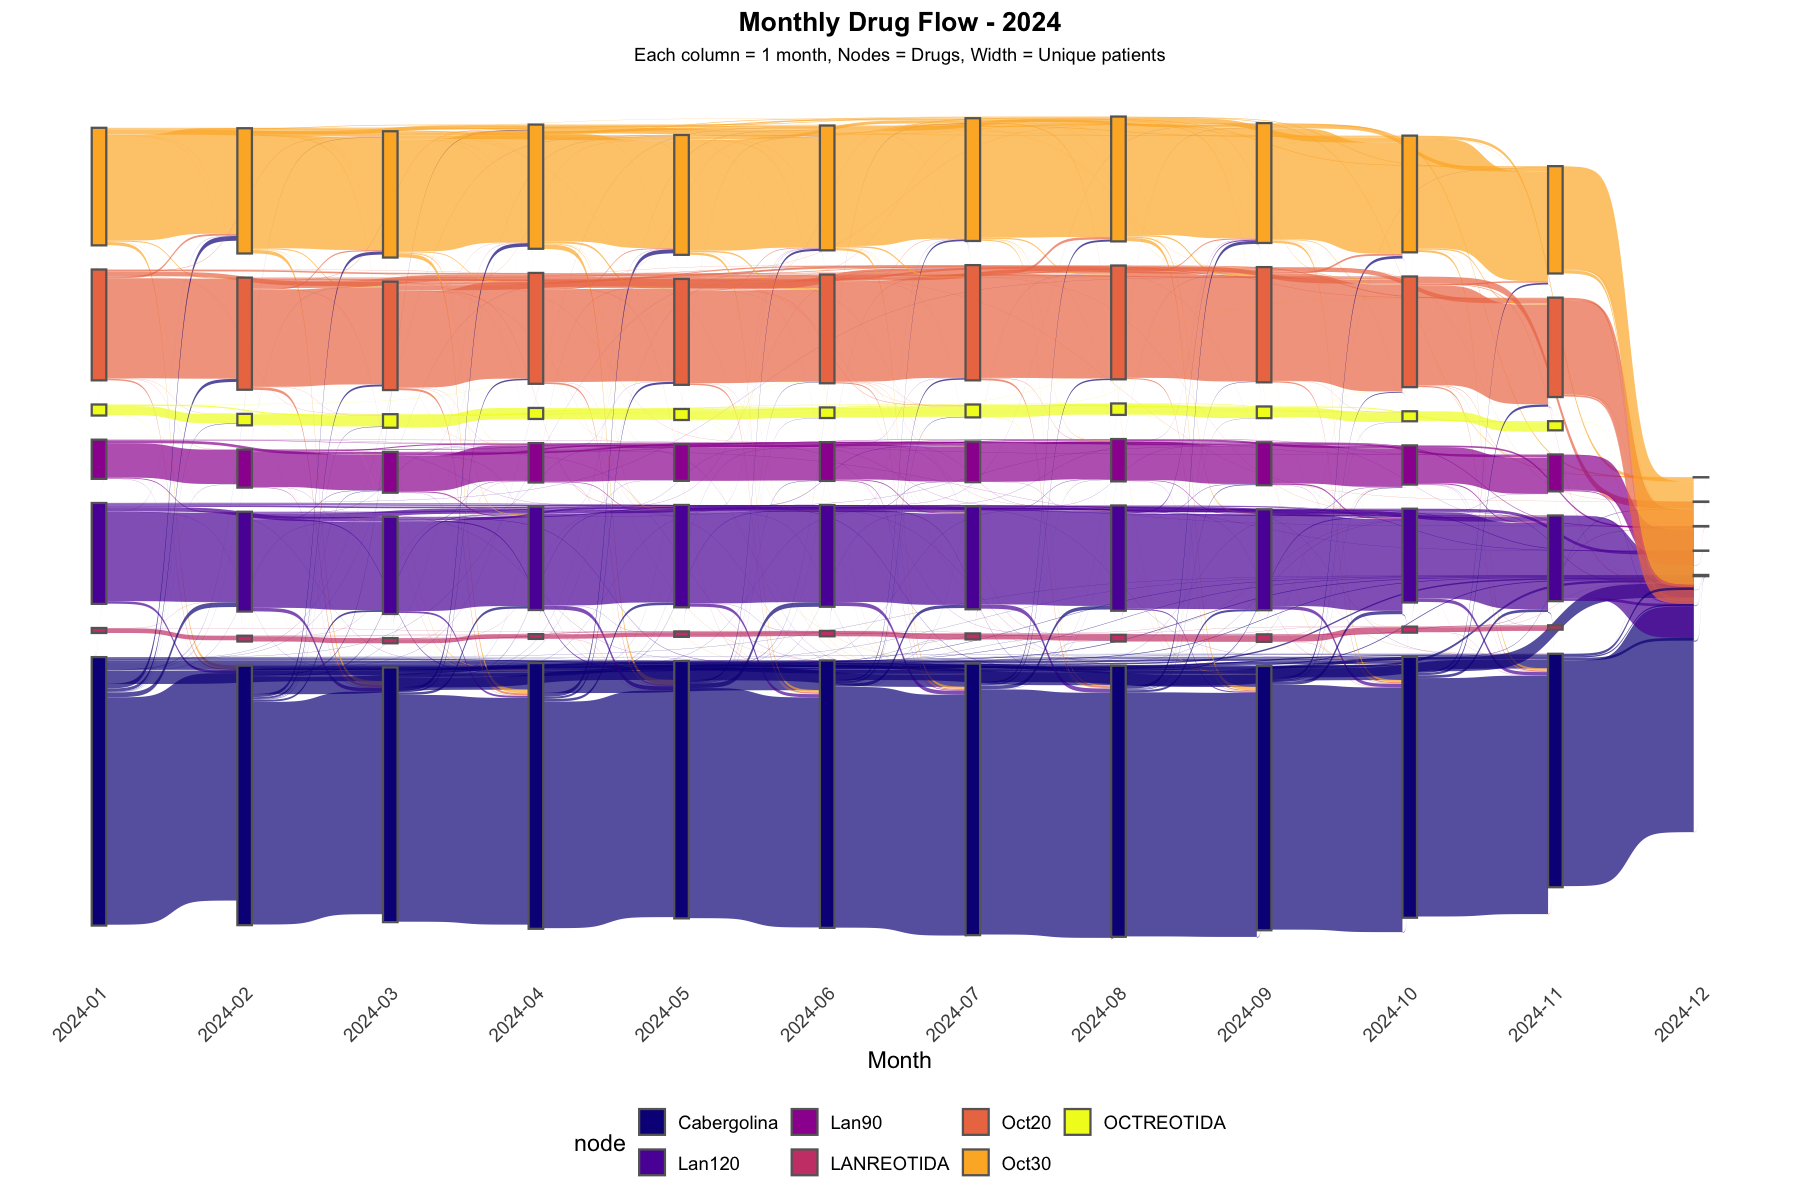

In [27]:
# Sankey - Fluxo de Medicamentos Mês a Mês
library(tidyverse)
library(ggsankey)

cat("=== DIAGRAMA DE SANKEY - FORÇANDO ORDENAÇÃO E FLUXO ===\n")

# 1. Preparar dados com pacientes e medicamentos por mês (inalterado)
dados <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL) & !is.na(AP_CNSPCN)) %>%
  mutate(
    medicamento = recode(as.character(AP_PRIPAL), !!!codigo_nomes),
    mes = format(AP_CMP, "%Y-%m"),
    med_nome = case_when(
      str_detect(medicamento, "CABERGOLINA") ~ "Cabergolina",
      str_detect(medicamento, "LANREOTIDA 120") ~ "Lan120",
      str_detect(medicamento, "LANREOTIDA 90") ~ "Lan90",
      str_detect(medicamento, "OCTREOTIDA LAR 30") ~ "Oct30",
      str_detect(medicamento, "OCTREOTIDA LAR 20") ~ "Oct20",
      TRUE ~ substr(medicamento, 1, 10)
    )
  ) %>%
  filter(!is.na(medicamento)) %>%
  select(AP_CNSPCN, mes, med_nome) %>%
  distinct() %>%
  arrange(AP_CNSPCN, mes)

cat("Total registros:", nrow(dados), "\n")

# 2. Criar a tabela de Transições Mês-a-Mês (Flow Table)
trans <- dados %>%
  group_by(AP_CNSPCN) %>%
  arrange(mes) %>%
  mutate(
    mes_proximo = lead(mes),
    med_proximo = lead(med_nome)
  ) %>%
  ungroup() %>%
  filter(!is.na(mes_proximo)) %>%
  select(AP_CNSPCN, mes_atual = mes, mes_proximo, med_atual = med_nome, med_proximo)

cat("Total de transições:", nrow(trans), "\n")

# 3. Agregar fluxos, formatar e FORÇAR A ORDENAÇÃO
dados_sankey <- trans %>%
  group_by(mes_atual, med_atual, mes_proximo, med_proximo) %>%
  summarise(value = n_distinct(AP_CNSPCN), .groups = "drop") %>%
  arrange(mes_atual, mes_proximo) %>%
  
  # Renomear colunas para o formato Sankey
  select(
    x = mes_atual,
    next_x = mes_proximo, 
    node = med_atual,
    next_node = med_proximo,
    value = value
  ) %>%
  
  # ADIÇÃO CHAVE: Forçar 'x' e 'next_x' a serem fatores ordenados (meses)
  # Isso garante que a ordem no eixo X seja respeitada e o fluxo seja traçado sequencialmente.
  mutate(
    x = factor(x, levels = unique(dados$mes)),
    next_x = factor(next_x, levels = unique(dados$mes))
  )

cat("Fluxos únicos (pronto para plotar):", nrow(dados_sankey), "\n")
cat("\nPreparando dados para Sankey...\n")
print(head(dados_sankey, 10))

# 4. Plotar Sankey
cat("\nPlotando Sankey com", length(unique(dados_sankey$x)), "colunas (meses)...\n")

p <- ggplot(dados_sankey, aes(x = x, 
                              next_x = next_x,
                              node = node,
                              next_node = next_node,
                              fill = node,
                              value = value)) +
  # Se o fluxo for muito pequeno (valor < 1), ele não aparece. 
  # O 'value' é a espessura. Com n_distinct(AP_CNSPCN), deve ser >= 1.
  geom_sankey(flow.alpha = 0.7, node.color = "gray40", smooth = 8) +
  scale_fill_viridis_d(option = "plasma") +
  theme_sankey(base_size = 14) +
  labs(
    title = "Monthly Drug Flow - 2024",
    x = "Month",
    subtitle = "Each column = 1 month, Nodes = Drugs, Width = Unique patients"
  ) +
  theme(
    plot.title = element_text(face = "bold", size = 16, hjust = 0.5),
    plot.subtitle = element_text(size = 11, hjust = 0.5),
    legend.position = "bottom",
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

print(p)
cat("\n✅ DIAGRAMA DE SANKEY CRIADO COM AS LINHAS DE FLUXO (Ordenação forçada aplicada)!\n")

In [28]:
# Certifique-se de que o pacote 'writexl' esteja instalado:
# install.packages("writexl")
library(writexl)
library(ggplot2) # Necessário para o ggsave

# --- CONFIGURAÇÕES DE SALVAMENTO ---

# 1. Definir o caminho de destino (Mantenha o final com /)
diretorio_destino <- "/Users/daniellybx/Documents/Projetos LEFAR:FS:UnB CNPq/projetos_lefar/data/processed/"

# 2. Gerar a data de hoje no formato YYYYMMDD_
# Usamos Sys.Date() para pegar a data atual do sistema.
data_hoje <- format(Sys.Date(), "%Y%m%d_")

# 3. Definir o nome base dos arquivos
nome_base <- "acromegalia_diagrama_sankey"
nome_tabela <- paste0(data_hoje, nome_base, "_tabela.xlsx")
nome_grafico <- paste0(data_hoje, nome_base, ".png")

# 4. Criar o caminho completo dos arquivos
caminho_tabela <- file.path(diretorio_destino, nome_tabela)
caminho_grafico <- file.path(diretorio_destino, nome_grafico)


# --- SALVAR O ARQUIVO EXCEL ---

cat("\nSalvando tabela de fluxo em:", caminho_tabela, "\n")
tryCatch({
  write_xlsx(dados_sankey, path = caminho_tabela)
  cat("✅ Tabela de Sankey salva com sucesso no formato .xlsx!\n")
}, error = function(e) {
  cat("❌ ERRO ao salvar a tabela Excel: Verifique se o pacote 'writexl' está instalado e se o diretório existe.\n")
  print(e)
})


# --- SALVAR O GRÁFICO ---

cat("\nSalvando diagrama de Sankey em:", caminho_grafico, "\n")
tryCatch({
  # Usamos ggsave para salvar o objeto ggplot (p)
  # Definimos largura e altura para garantir a qualidade
  ggsave(
    filename = caminho_grafico,
    plot = p,
    width = 15,    # Ajuste se o gráfico estiver muito estreito/largo
    height = 10,   # Ajuste se o gráfico estiver muito baixo/alto
    units = "in",  # Unidades em polegadas
    dpi = 300      # Alta resolução
  )
  cat("✅ Diagrama de Sankey salvo com sucesso no formato .png!\n")
}, error = function(e) {
  cat("❌ ERRO ao salvar o gráfico: Verifique se o diretório existe e se o objeto 'p' foi gerado corretamente.\n")
  print(e)
})

cat("\n--- FIM DO PROCESSO DE SALVAMENTO ---\n")


Salvando tabela de fluxo em: /Users/daniellybx/Documents/Projetos LEFAR:FS:UnB CNPq/projetos_lefar/data/processed//20260720_acromegalia_diagrama_sankey_tabela.xlsx 
❌ ERRO ao salvar a tabela Excel: Verifique se o pacote 'writexl' está instalado e se o diretório existe.
<simpleError: Error in libxlsxwriter: 'Error creating output xlsx file. Usually a permissions error.'>

Salvando diagrama de Sankey em: /Users/daniellybx/Documents/Projetos LEFAR:FS:UnB CNPq/projetos_lefar/data/processed//20260720_acromegalia_diagrama_sankey.png 
❌ ERRO ao salvar o gráfico: Verifique se o diretório existe e se o objeto 'p' foi gerado corretamente.
<error/rlang_error>
Error in `ggsave()`:
! Cannot find directory /Users/daniellybx/Documents/Projetos
  LEFAR:FS:UnB CNPq/projetos_lefar/data/processed.
ℹ Please supply an existing directory or use `create.dir = TRUE`.
---
Backtrace:
     ▆
  1. ├─IRkernel::main()
  2. │ └─kernel$run()
  3. │   └─IRkernel (local) handle_shell()
  4. │     └─executor$execute(ms

#### 7.4.2 - Gráfico Alluvial de Fluxo de Medicamentos por Paciente

=== GRÁFICO ALLUVIAL - FLUXO DE MEDICAMENTOS POR PACIENTE ===


Loading required package: ggalluvial



Total de registros para alluvial: 96 
Meses únicos: 12 
Medicamentos únicos: 8 

Medicamentos e cores atribuídas:
  1. CABERGOLINA 0,5 MG: #E64B35
  2. LANREOTIDA 120 MG INJETÁVEL: #4DBBD5
  3. LANREOTIDA 60 MG INJETÁVEL: #00A087
  4. LANREOTIDA 90 MG INJETÁVEL: #3C5488
  5. OCTREOTIDA 0,1 MG/ML INJETÁVEL: #F39B7F
  6. OCTREOTIDA LAR 10 MG INJETÁVEL: #8491B4
  7. OCTREOTIDA LAR 20 MG INJETÁVEL: #91D1C2
  8. OCTREOTIDA LAR 30 MG INJETÁVEL: #DC0000

Preparando dados para alluvial...
Pacientes únicos no dataset alluvial: 4231 

Plotando gráfico alluvial...


Warning message in geom_alluvium(aes(fill = Janeiro), alpha = 0.65, width = 1/12, :
“Ignoring unknown parameters: `smooth`”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”



✅ GRÁFICO ALLUVIAL CRIADO COM SUCESSO!

Salvando gráfico alluvial 7.4.2 em: ../resultados/20260720_dados2024_acromegalia_alluvial_742.png 


Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”


✅ Gráfico alluvial 7.4.2 salvo com sucesso em: ../resultados/20260720_dados2024_acromegalia_alluvial_742.png 

--- FIM DO PROCESSO DE CRIAÇÃO DO GRÁFICO ALLUVIAL ---


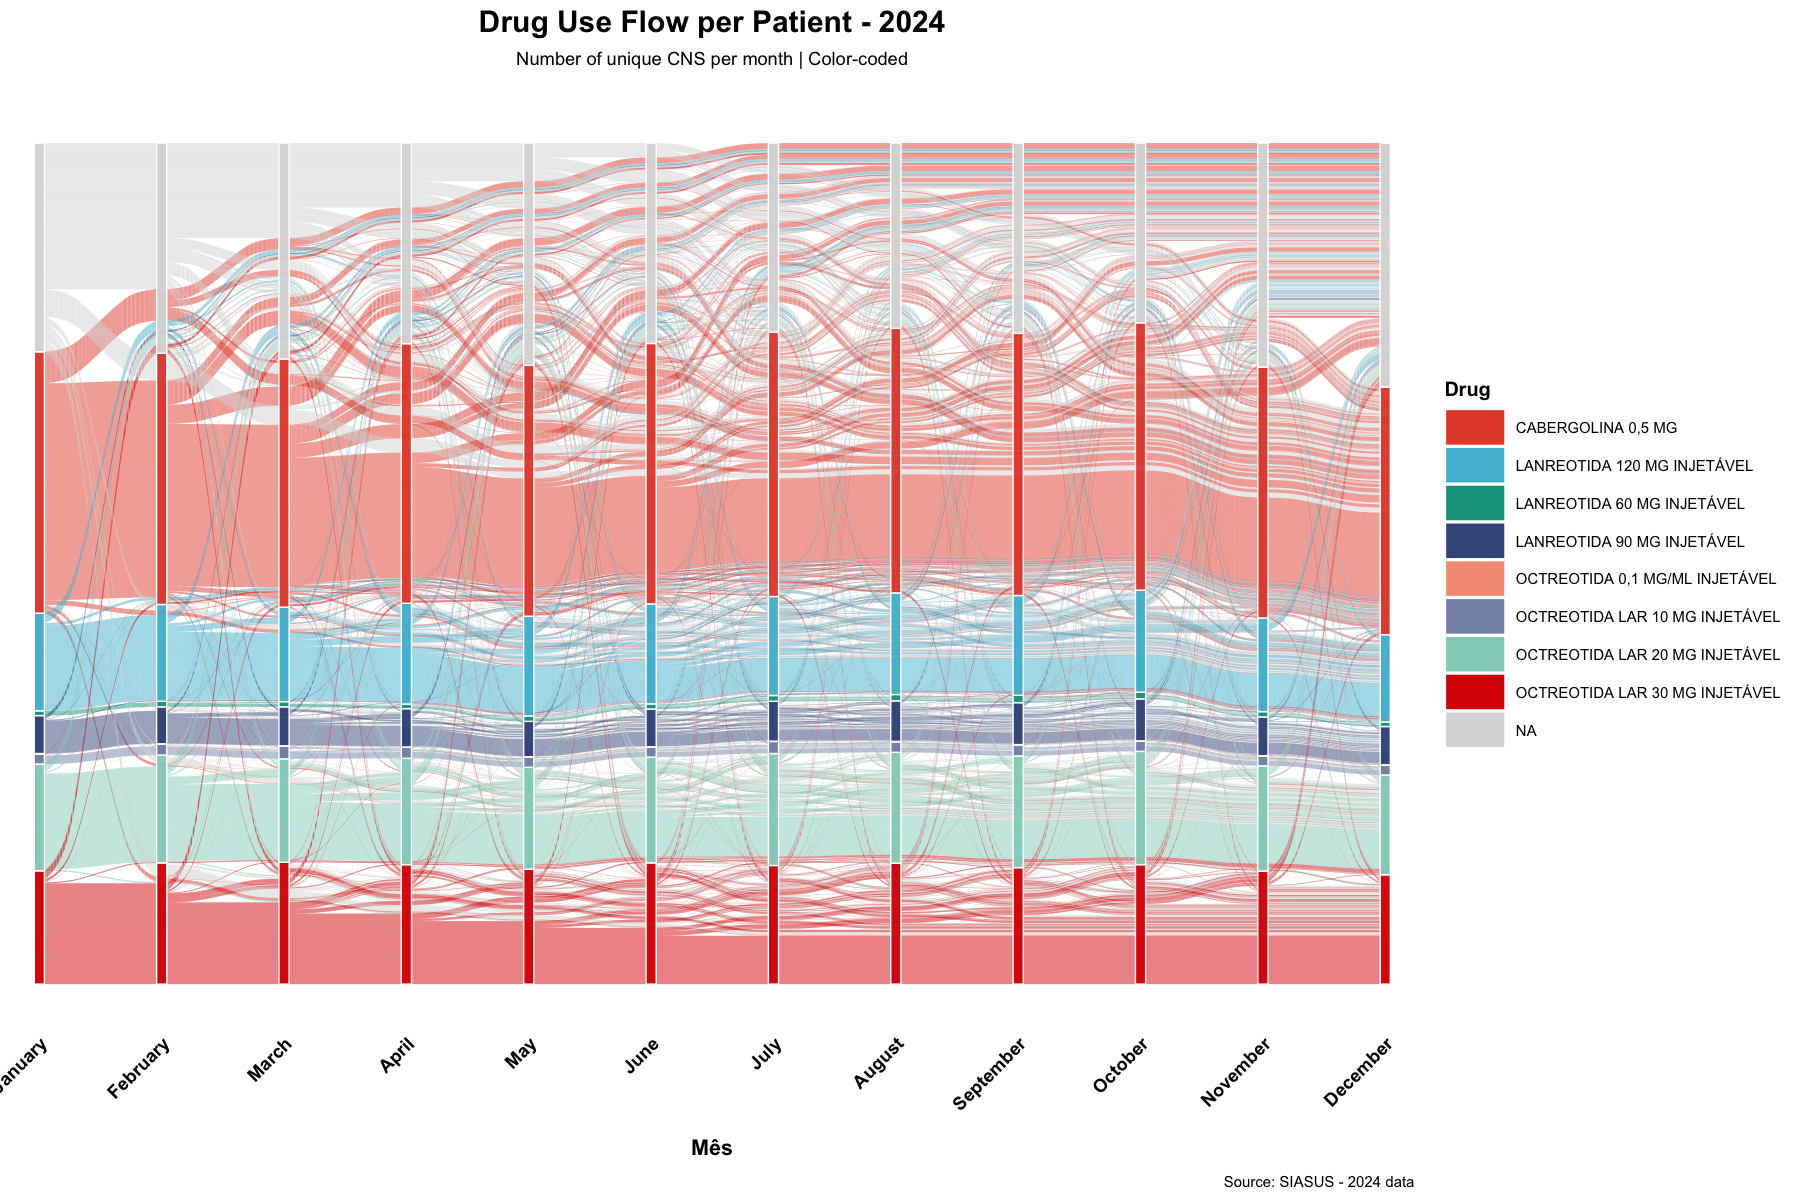

In [29]:
# Gráfico Alluvial - Fluxo de Medicamentos por Paciente
# Contando CNS únicos por mês (janeiro a dezembro de 2024)

cat("=== GRÁFICO ALLUVIAL - FLUXO DE MEDICAMENTOS POR PACIENTE ===\n")

# Carregar pacote ggalluvial se necessário
if (!require(ggalluvial)) {
  install.packages("ggalluvial")
  library(ggalluvial)
}

# Preparar dados: contar CNS únicos por mês e medicamento padronizado
dados_alluvial <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL) & !is.na(AP_CNSPCN)) %>%
  filter(AP_CMP >= as.Date("2024-01-01") & AP_CMP <= as.Date("2024-12-31")) %>%
  mutate(
    medicamento = recode(as.character(AP_PRIPAL), !!!codigo_nomes),
    mes = format(AP_CMP, "%Y-%m"),
    mes_num = as.numeric(format(AP_CMP, "%m"))
  ) %>%
  filter(!is.na(medicamento)) %>%
  # Padronizar nomes dos medicamentos (usar nomes completos)
  mutate(
    medicamento_padronizado = case_when(
      str_detect(medicamento, "CABERGOLINA") ~ "CABERGOLINA 0,5 MG",
      str_detect(medicamento, "LANREOTIDA 120") ~ "LANREOTIDA 120 MG INJETÁVEL",
      str_detect(medicamento, "LANREOTIDA 90") ~ "LANREOTIDA 90 MG INJETÁVEL",
      str_detect(medicamento, "LANREOTIDA 60") ~ "LANREOTIDA 60 MG INJETÁVEL",
      str_detect(medicamento, "OCTREOTIDA LAR 30") ~ "OCTREOTIDA LAR 30 MG INJETÁVEL",
      str_detect(medicamento, "OCTREOTIDA LAR 20") ~ "OCTREOTIDA LAR 20 MG INJETÁVEL",
      str_detect(medicamento, "OCTREOTIDA LAR 10") ~ "OCTREOTIDA LAR 10 MG INJETÁVEL",
      str_detect(medicamento, "OCTREOTIDA 0,1") ~ "OCTREOTIDA 0,1 MG/ML INJETÁVEL",
      TRUE ~ medicamento
    )
  ) %>%
  # Contar CNS únicos por mês e medicamento
  group_by(mes, mes_num, medicamento_padronizado) %>%
  summarise(
    quantidade_cns = n_distinct(AP_CNSPCN),
    .groups = "drop"
  ) %>%
  # Garantir ordem correta dos meses
  arrange(mes_num, medicamento_padronizado)

cat("Total de registros para alluvial:", nrow(dados_alluvial), "\n")
cat("Meses únicos:", length(unique(dados_alluvial$mes)), "\n")
cat("Medicamentos únicos:", length(unique(dados_alluvial$medicamento_padronizado)), "\n")

# Criar paleta de cores para cada medicamento
medicamentos_unicos <- sort(unique(dados_alluvial$medicamento_padronizado))
n_medicamentos <- length(medicamentos_unicos)

# Paleta de cores distinta e harmoniosa
cores_medicamentos <- c(
  "#E64B35", "#4DBBD5", "#00A087", "#3C5488", "#F39B7F",
  "#8491B4", "#91D1C2", "#DC0000", "#7E6148", "#B09C85"
)

# Ajustar tamanho da paleta se necessário
if (n_medicamentos > length(cores_medicamentos)) {
  cores_medicamentos <- colorRampPalette(cores_medicamentos)(n_medicamentos)
} else {
  cores_medicamentos <- cores_medicamentos[1:n_medicamentos]
}

names(cores_medicamentos) <- medicamentos_unicos

cat("\nMedicamentos e cores atribuídas:\n")
for (i in 1:length(medicamentos_unicos)) {
  cat(sprintf("  %d. %s: %s\n", i, medicamentos_unicos[i], cores_medicamentos[i]))
}

# Preparar dados no formato adequado para alluvial
# Para cada paciente, criar uma sequência de medicamentos por mês
dados_pacientes_mes <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL) & !is.na(AP_CNSPCN)) %>%
  filter(AP_CMP >= as.Date("2024-01-01") & AP_CMP <= as.Date("2024-12-31")) %>%
  mutate(
    medicamento = recode(as.character(AP_PRIPAL), !!!codigo_nomes),
    mes = format(AP_CMP, "%Y-%m"),
    mes_num = as.numeric(format(AP_CMP, "%m"))
  ) %>%
  filter(!is.na(medicamento)) %>%
  mutate(
    medicamento_padronizado = case_when(
      str_detect(medicamento, "CABERGOLINA") ~ "CABERGOLINA 0,5 MG",
      str_detect(medicamento, "LANREOTIDA 120") ~ "LANREOTIDA 120 MG INJETÁVEL",
      str_detect(medicamento, "LANREOTIDA 90") ~ "LANREOTIDA 90 MG INJETÁVEL",
      str_detect(medicamento, "LANREOTIDA 60") ~ "LANREOTIDA 60 MG INJETÁVEL",
      str_detect(medicamento, "OCTREOTIDA LAR 30") ~ "OCTREOTIDA LAR 30 MG INJETÁVEL",
      str_detect(medicamento, "OCTREOTIDA LAR 20") ~ "OCTREOTIDA LAR 20 MG INJETÁVEL",
      str_detect(medicamento, "OCTREOTIDA LAR 10") ~ "OCTREOTIDA LAR 10 MG INJETÁVEL",
      str_detect(medicamento, "OCTREOTIDA 0,1") ~ "OCTREOTIDA 0,1 MG/ML INJETÁVEL",
      TRUE ~ medicamento
    )
  ) %>%
  select(AP_CNSPCN, mes, mes_num, medicamento_padronizado) %>%
  distinct() %>%
  arrange(AP_CNSPCN, mes_num)

# Criar formato wide: uma linha por paciente com colunas para cada mês
dados_alluvial_wide <- dados_pacientes_mes %>%
  # Para cada paciente, pegar o medicamento de cada mês (se houver múltiplos, pegar o primeiro)
  group_by(AP_CNSPCN, mes_num) %>%
  summarise(medicamento = first(medicamento_padronizado), .groups = "drop") %>%
  # Transformar em formato wide
  pivot_wider(
    names_from = mes_num,
    values_from = medicamento,
    names_prefix = "Mes_",
    values_fill = NA
  ) %>%
  # Renomear colunas com nomes dos meses
  rename(
    Janeiro = Mes_1, Fevereiro = Mes_2, Março = Mes_3, Abril = Mes_4,
    Maio = Mes_5, Junho = Mes_6, Julho = Mes_7, Agosto = Mes_8,
    Setembro = Mes_9, Outubro = Mes_10, Novembro = Mes_11, Dezembro = Mes_12
  ) %>%
  # Remover pacientes que não têm medicamento em nenhum mês
  filter(!if_all(c(Janeiro, Fevereiro, Março, Abril, Maio, Junho,
                   Julho, Agosto, Setembro, Outubro, Novembro, Dezembro), is.na))

cat("\nPreparando dados para alluvial...\n")
cat("Pacientes únicos no dataset alluvial:", nrow(dados_alluvial_wide), "\n")

# Plotar gráfico alluvial
cat("\nPlotando gráfico alluvial...\n")

# Criar gráfico alluvial limpo - sem labels, apenas cores nos nós e fluxos
p_alluvial <- ggplot(dados_alluvial_wide,
                     aes(axis1 = Janeiro, axis2 = Fevereiro, axis3 = Março,
                         axis4 = Abril, axis5 = Maio, axis6 = Junho,
                         axis7 = Julho, axis8 = Agosto, axis9 = Setembro,
                         axis10 = Outubro, axis11 = Novembro, axis12 = Dezembro)) +
  # Fluxos alluviais com cor baseada no medicamento do primeiro mês
  geom_alluvium(aes(fill = Janeiro), alpha = 0.65, width = 1/12, 
                curve_type = "spline", smooth = 8) +
  # Nós (stratum) coloridos pelo medicamento - cada nó mostra a cor do medicamento
  # Usar fill baseado no valor do stratum (medicamento)
  geom_stratum(aes(fill = after_stat(stratum)), width = 1/12, 
              color = "white", size = 0.4, alpha = 0.95) +
  # SEM labels - completamente removido
  scale_x_discrete(limits = c("Janeiro", "Fevereiro", "Março", "Abril", "Maio", "Junho",
                              "Julho", "Agosto", "Setembro", "Outubro", "Novembro", "Dezembro"),
                   labels = c("January", "February", "March", "April", "May", "June",
                              "July", "August", "September", "October", "November", "December"),
                   expand = c(0.02, 0.02)) +
  scale_fill_manual(values = cores_medicamentos, name = "Drug", 
                    na.value = "grey85", 
                    guide = guide_legend(ncol = 1, 
                                        override.aes = list(alpha = 0.9, size = 0.5),
                                        title.position = "top")) +
  labs(
    title = "Drug Use Flow per Patient - 2024",
    subtitle = "Number of unique CNS per month | Color-coded",
    x = "Mês",
    y = "",
    fill = "Medicamento",
    caption = "Source: SIASUS - 2024 data"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title = element_text(size = 18, face = "bold", hjust = 0.5, margin = margin(b = 8)),
    plot.subtitle = element_text(size = 11, hjust = 0.5, margin = margin(b = 20)),
    axis.text.x = element_text(angle = 45, hjust = 1, size = 11, face = "bold", color = "black"),
    axis.text.y = element_blank(),
    axis.title.x = element_text(size = 13, face = "bold", margin = margin(t = 15)),
    axis.title.y = element_blank(),
    axis.ticks = element_blank(),
    legend.position = "right",
    legend.text = element_text(size = 9),
    legend.title = element_text(size = 12, face = "bold"),
    legend.key.size = unit(1.3, "cm"),
    legend.key.height = unit(0.8, "cm"),
    panel.grid = element_blank(),
    plot.caption = element_text(size = 9, hjust = 1, margin = margin(t = 10)),
    plot.background = element_rect(fill = "white", color = NA),
    panel.background = element_rect(fill = "white", color = NA)
  )

print(p_alluvial)

cat("\n✅ GRÁFICO ALLUVIAL CRIADO COM SUCESSO!\n")

# Salvar gráfico 7.4.2 na pasta resultados
tryCatch({
  caminho_grafico <- gerar_nome_png("acromegalia_alluvial_742")
  cat("\nSalvando gráfico alluvial 7.4.2 em:", caminho_grafico, "\n")
  
  ggsave(
    filename = caminho_grafico,
    plot = p_alluvial,
    width = 24,
    height = 14,
    units = "in",
    dpi = 300
  )
  cat("✅ Gráfico alluvial 7.4.2 salvo com sucesso em:", caminho_grafico, "\n")
}, error = function(e) {
  cat("❌ ERRO ao salvar o gráfico 7.4.2: Verifique se o diretório existe e se o objeto 'p_alluvial' foi gerado corretamente.\n")
  print(e)
})

cat("\n--- FIM DO PROCESSO DE CRIAÇÃO DO GRÁFICO ALLUVIAL ---\n")

#### 7.4.3 - Gráfico Alluvial de Fluxo de Medicamentos (Apenas Períodos de Uso)

=== 7.4.3 - GRÁFICO ALLUVIAL - Apenas meses com uso ===
Pacientes únicos no dataset alluvial (apenas uso): 4231 


Warning message in geom_alluvium(aes(fill = Janeiro), alpha = 0.65, width = 1/12, :
“Ignoring unknown parameters: `smooth`”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”



✅ GRÁFICO ALLUVIAL 7.4.3 CRIADO COM SUCESSO!

Salvando gráfico alluvial 7.4.3 em: ../resultados/20260720_dados2024_acromegalia_alluvial_743.png 


Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”


✅ Gráfico alluvial 7.4.3 salvo com sucesso em: ../resultados/20260720_dados2024_acromegalia_alluvial_743.png 

--- FIM DO PROCESSO DE CRIAÇÃO DO GRÁFICO ALLUVIAL 7.4.3 ---


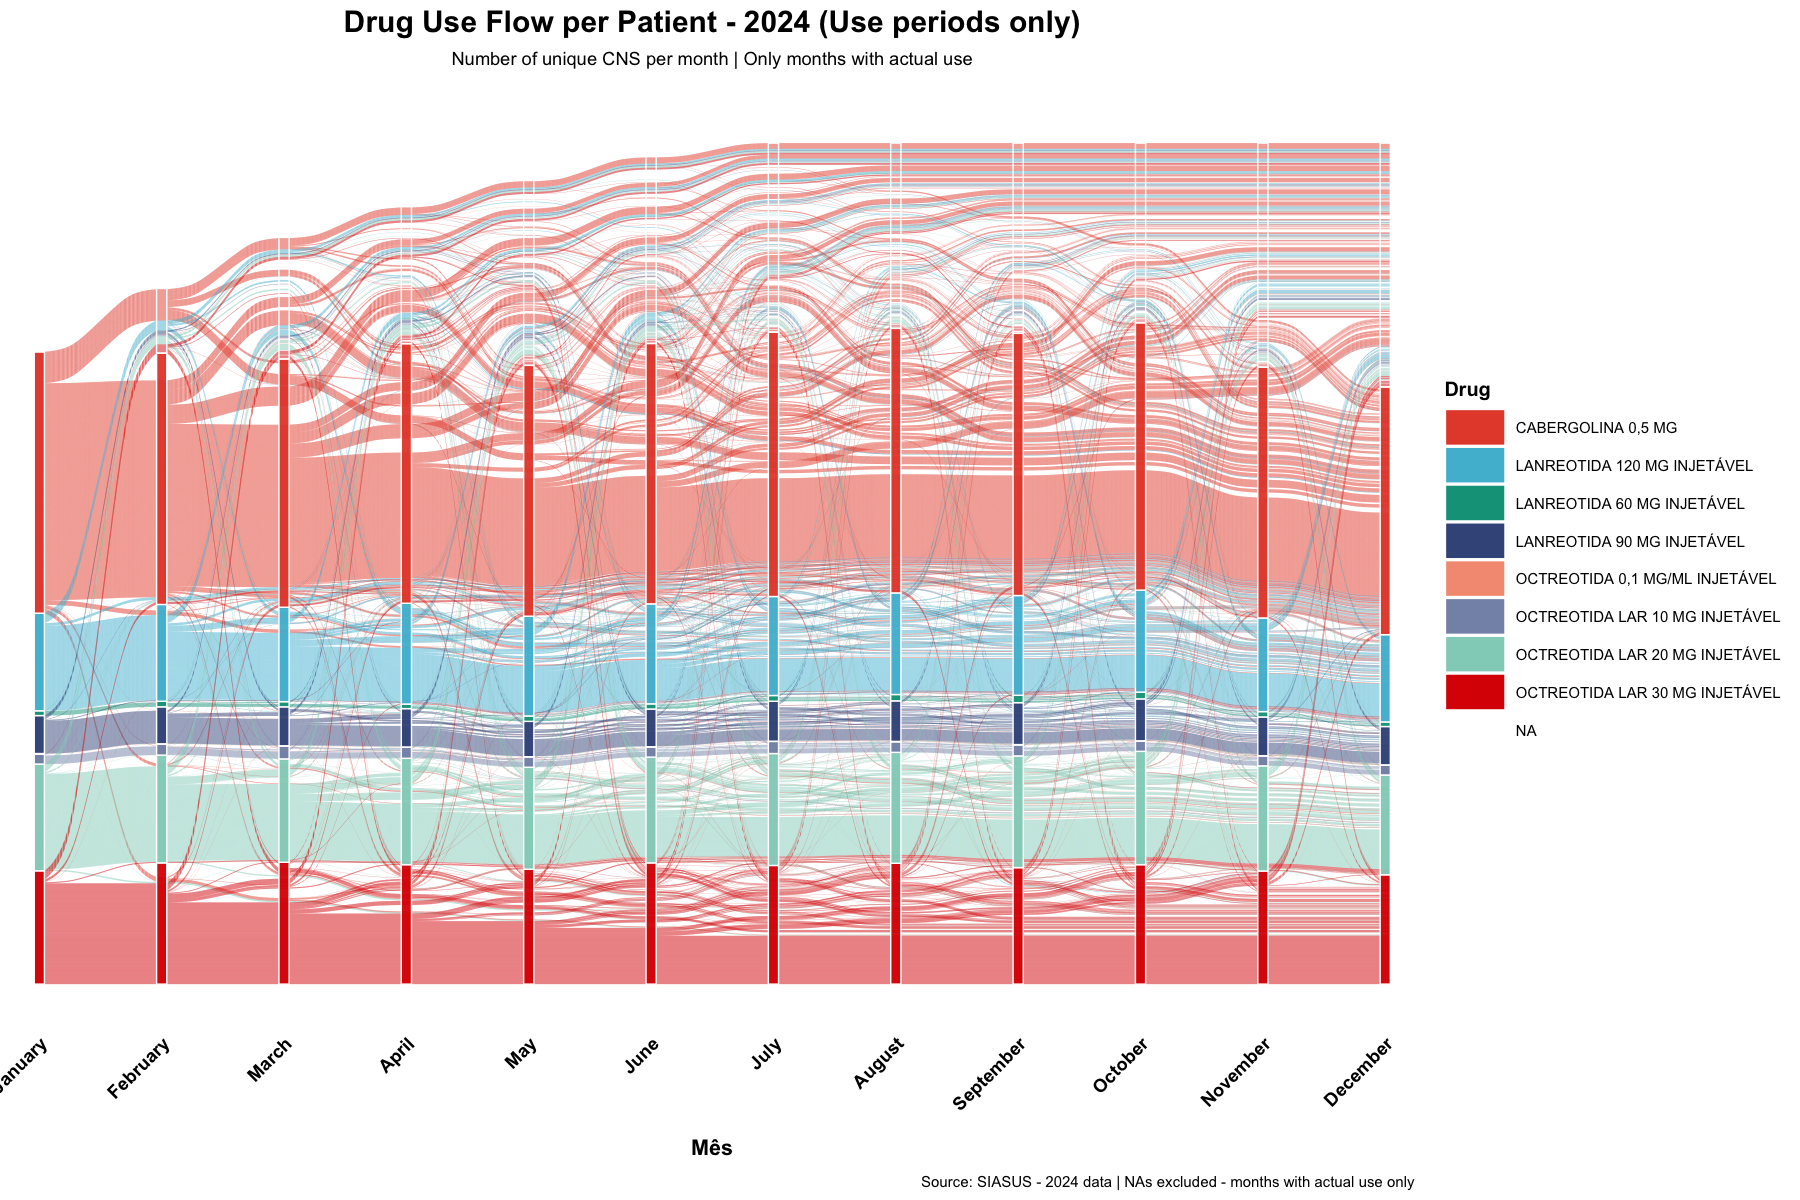

In [30]:
cat("=== 7.4.3 - GRÁFICO ALLUVIAL - Apenas meses com uso ===\n")

# Preparar dados apenas com meses em que o paciente estava usando medicamento
# Remover COMPLETAMENTE os NAs - considerar apenas períodos de uso efetivo
# Se um CNS não estava usando antes ou deixou depois, contar apenas os meses de uso
dados_alluvial_uso <- dados_pacientes_mes %>%
  # Filtrar apenas registros válidos (sem NA) - apenas meses com uso
  filter(!is.na(medicamento_padronizado)) %>%
  # Para cada paciente, pegar o medicamento de cada mês em que estava usando
  group_by(AP_CNSPCN, mes_num) %>%
  summarise(medicamento = first(medicamento_padronizado), .groups = "drop") %>%
  # Transformar em formato wide - NÃO preencher com NA, deixar vazio onde não há uso
  pivot_wider(
    names_from = mes_num,
    values_from = medicamento,
    names_prefix = "Mes_"
    # NÃO usar values_fill = NA - deixar como NULL onde não há medicamento
  ) %>%
  # Renomear colunas com nomes dos meses
  rename(
    Janeiro = Mes_1, Fevereiro = Mes_2, Março = Mes_3, Abril = Mes_4,
    Maio = Mes_5, Junho = Mes_6, Julho = Mes_7, Agosto = Mes_8,
    Setembro = Mes_9, Outubro = Mes_10, Novembro = Mes_11, Dezembro = Mes_12
  ) %>%
  # Remover pacientes que não têm medicamento em nenhum mês
  filter(!if_all(c(Janeiro, Fevereiro, Março, Abril, Maio, Junho,
                   Julho, Agosto, Setembro, Outubro, Novembro, Dezembro), is.na)) %>%
  # Filtrar linhas onde há pelo menos um mês com uso
  filter(rowSums(!is.na(select(., Janeiro:Dezembro))) > 0)
  # Manter apenas valores válidos (não NA) - os NAs serão ignorados pelo ggalluvial
  # Não converter para string vazia, deixar como NA mas garantir que não apareçam como categoria

cat("Pacientes únicos no dataset alluvial (apenas uso):", nrow(dados_alluvial_uso), "\n")

# Criar segundo gráfico alluvial - apenas meses com uso
p_alluvial_uso <- ggplot(dados_alluvial_uso,
                         aes(axis1 = Janeiro, axis2 = Fevereiro, axis3 = Março,
                             axis4 = Abril, axis5 = Maio, axis6 = Junho,
                             axis7 = Julho, axis8 = Agosto, axis9 = Setembro,
                             axis10 = Outubro, axis11 = Novembro, axis12 = Dezembro)) +
  # Fluxos alluviais com cor baseada no medicamento do primeiro mês com uso
  geom_alluvium(aes(fill = Janeiro), alpha = 0.65, width = 1/12, 
                curve_type = "spline", smooth = 8) +
  # Nós (stratum) coloridos pelo medicamento - apenas onde há uso
  geom_stratum(aes(fill = after_stat(stratum)), width = 1/12, 
              color = "white", size = 0.4, alpha = 0.95) +
  # SEM labels
  scale_x_discrete(limits = c("Janeiro", "Fevereiro", "Março", "Abril", "Maio", "Junho",
                              "Julho", "Agosto", "Setembro", "Outubro", "Novembro", "Dezembro"),
                   labels = c("January", "February", "March", "April", "May", "June",
                              "July", "August", "September", "October", "November", "December"),
                   expand = c(0.02, 0.02)) +
  scale_fill_manual(values = cores_medicamentos, name = "Drug", 
                    na.value = NA,  # NAs não devem aparecer
                    guide = guide_legend(ncol = 1, 
                                        override.aes = list(alpha = 0.9, size = 0.5),
                                        title.position = "top")) +
  labs(
    title = "Drug Use Flow per Patient - 2024 (Use periods only)",
    subtitle = "Number of unique CNS per month | Only months with actual use",
    x = "Mês",
    y = "",
    fill = "Medicamento",
    caption = "Source: SIASUS - 2024 data | NAs excluded - months with actual use only"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title = element_text(size = 18, face = "bold", hjust = 0.5, margin = margin(b = 8)),
    plot.subtitle = element_text(size = 11, hjust = 0.5, margin = margin(b = 20)),
    axis.text.x = element_text(angle = 45, hjust = 1, size = 11, face = "bold", color = "black"),
    axis.text.y = element_blank(),
    axis.title.x = element_text(size = 13, face = "bold", margin = margin(t = 15)),
    axis.title.y = element_blank(),
    axis.ticks = element_blank(),
    legend.position = "right",
    legend.text = element_text(size = 9),
    legend.title = element_text(size = 12, face = "bold"),
    legend.key.size = unit(1.3, "cm"),
    legend.key.height = unit(0.8, "cm"),
    panel.grid = element_blank(),
    plot.caption = element_text(size = 9, hjust = 1, margin = margin(t = 10)),
    plot.background = element_rect(fill = "white", color = NA),
    panel.background = element_rect(fill = "white", color = NA)
  )

print(p_alluvial_uso)

cat("\n✅ GRÁFICO ALLUVIAL 7.4.3 CRIADO COM SUCESSO!\n")

# Salvar gráfico 7.4.3 na pasta resultados
tryCatch({
  caminho_grafico_uso <- gerar_nome_png("acromegalia_alluvial_743")
  cat("\nSalvando gráfico alluvial 7.4.3 em:", caminho_grafico_uso, "\n")
  
  ggsave(
    filename = caminho_grafico_uso,
    plot = p_alluvial_uso,
    width = 24,
    height = 14,
    units = "in",
    dpi = 300
  )
  cat("✅ Gráfico alluvial 7.4.3 salvo com sucesso em:", caminho_grafico_uso, "\n")
}, error = function(e) {
  cat("❌ ERRO ao salvar o gráfico 7.4.3: Verifique se o diretório existe.\n")
  print(e)
})

cat("\n--- FIM DO PROCESSO DE CRIAÇÃO DO GRÁFICO ALLUVIAL 7.4.3 ---\n")

#### 7.4.4 - Gráfico Alluvial de Fluxo de Medicamentos (Agrupado por Princípio Ativo)

=== 7.4.4 - GRAFICO ALLUVIAL - Agrupado por principio ativo ===
Pacientes únicos no dataset alluvial (agrupado por princípio ativo): 4231 


Warning message in geom_alluvium(aes(fill = Janeiro), alpha = 0.65, width = 1/12, :
“Ignoring unknown parameters: `smooth`”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”



✅ GRÁFICO ALLUVIAL 7.4.4 CRIADO COM SUCESSO!

Salvando gráfico alluvial 7.4.4 em: ../resultados/20260720_dados2024_acromegalia_alluvial_744.png 


Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”


✅ Gráfico alluvial 7.4.4 salvo com sucesso em: ../resultados/20260720_dados2024_acromegalia_alluvial_744.png 

--- FIM DO PROCESSO DE CRIAÇÃO DO GRÁFICO ALLUVIAL 7.4.4 ---


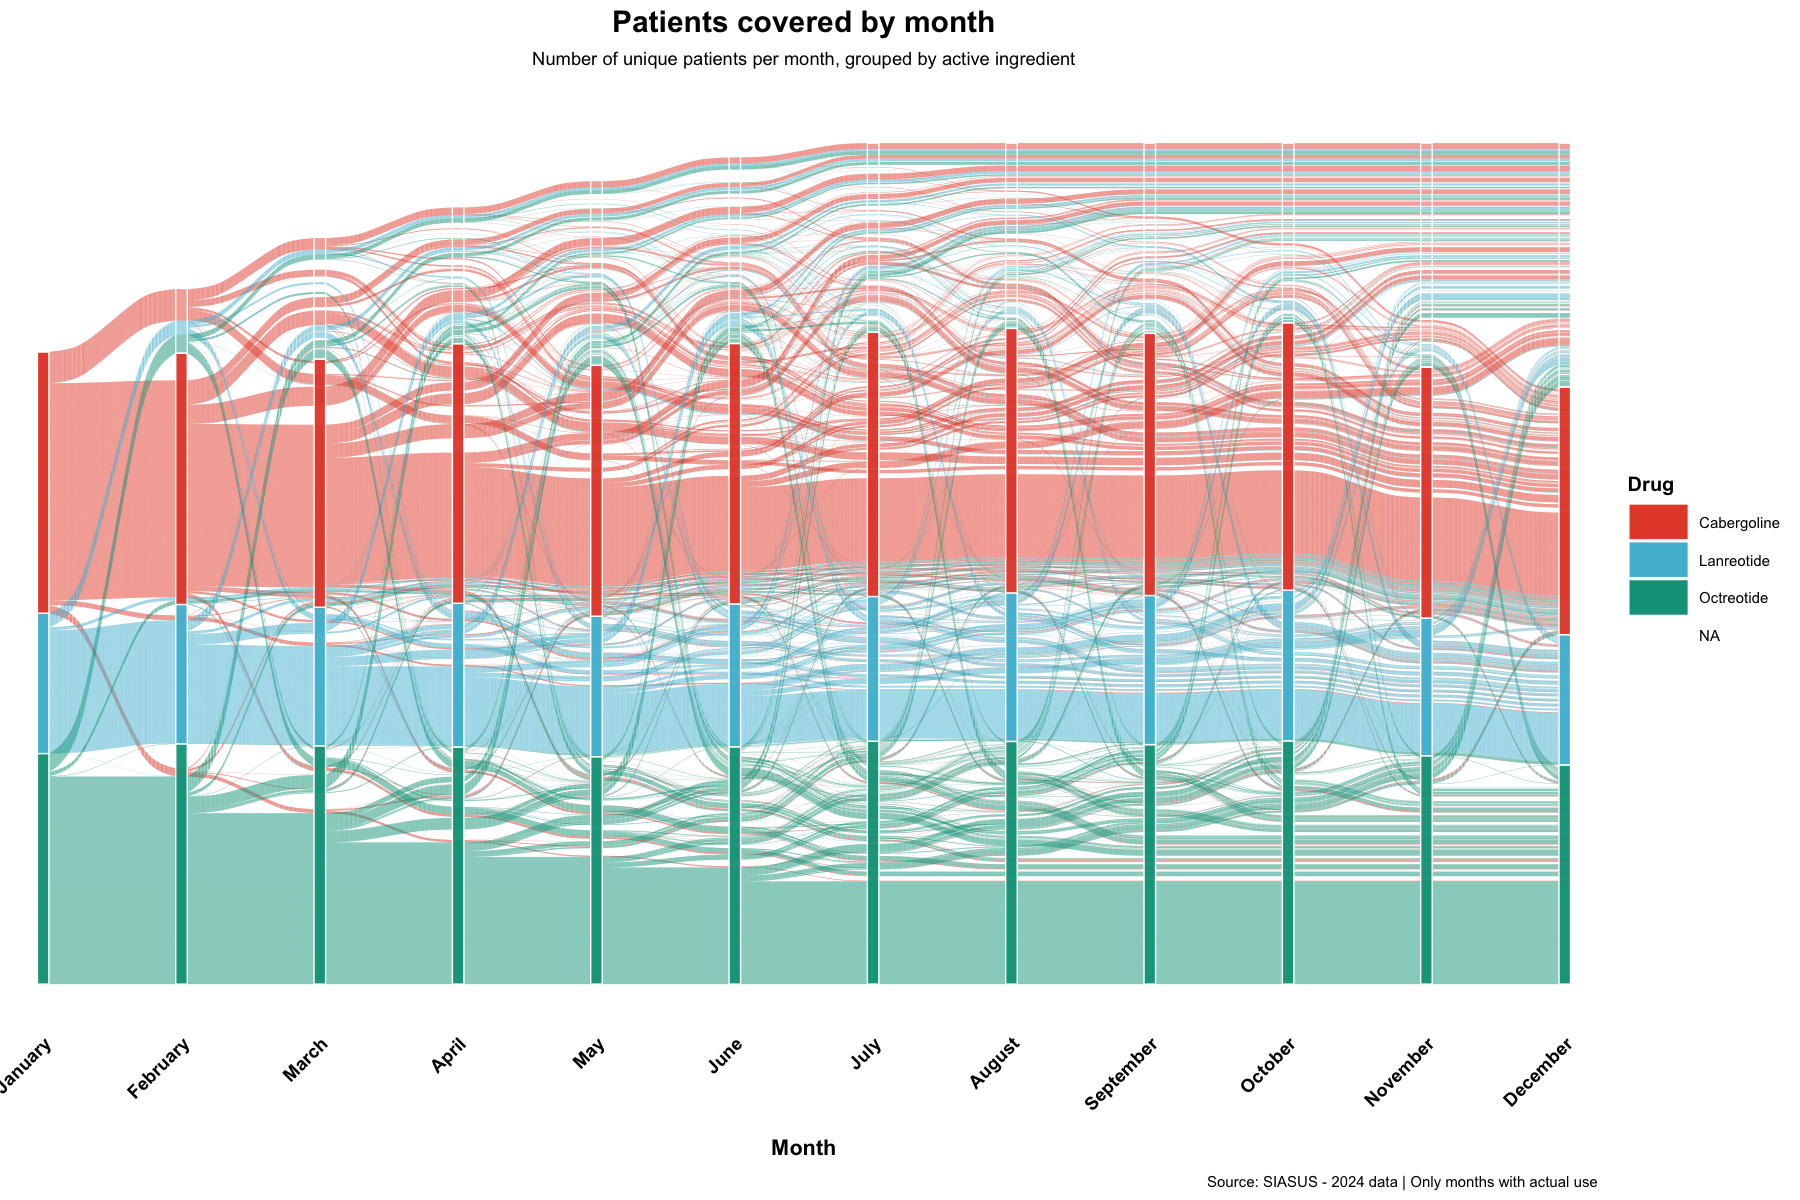

In [31]:
cat("=== 7.4.4 - GRAFICO ALLUVIAL - Agrupado por principio ativo ===\n")

# Agrupar os medicamentos padronizados (que distinguem dosagem) em apenas
# 3 categorias por principio ativo: Cabergoline, Lanreotide e Octreotide
dados_pacientes_mes_grupo <- dados_pacientes_mes %>%
  mutate(
    medicamento_grupo = case_when(
      str_detect(medicamento_padronizado, "CABERGOLINA") ~ "Cabergoline",
      str_detect(medicamento_padronizado, "LANREOTIDA") ~ "Lanreotide",
      str_detect(medicamento_padronizado, "OCTREOTIDA") ~ "Octreotide",
      TRUE ~ medicamento_padronizado
    )
  )

# Preparar dados apenas com meses em que o paciente estava de fato coberto
# pelo medicamento (mesma logica de periodos de uso do item 7.4.3)
dados_alluvial_grupo <- dados_pacientes_mes_grupo %>%
  filter(!is.na(medicamento_grupo)) %>%
  group_by(AP_CNSPCN, mes_num) %>%
  summarise(medicamento = first(medicamento_grupo), .groups = "drop") %>%
  pivot_wider(
    names_from = mes_num,
    values_from = medicamento,
    names_prefix = "Mes_"
  ) %>%
  rename(
    Janeiro = Mes_1, Fevereiro = Mes_2, Março = Mes_3, Abril = Mes_4,
    Maio = Mes_5, Junho = Mes_6, Julho = Mes_7, Agosto = Mes_8,
    Setembro = Mes_9, Outubro = Mes_10, Novembro = Mes_11, Dezembro = Mes_12
  ) %>%
  filter(!if_all(c(Janeiro, Fevereiro, Março, Abril, Maio, Junho,
                   Julho, Agosto, Setembro, Outubro, Novembro, Dezembro), is.na)) %>%
  filter(rowSums(!is.na(select(., Janeiro:Dezembro))) > 0)

cat("Pacientes únicos no dataset alluvial (agrupado por princípio ativo):", nrow(dados_alluvial_grupo), "\n")

# Paleta de cores - uma cor por princípio ativo
cores_grupo <- c(
  "Cabergoline" = "#E64B35",
  "Lanreotide"  = "#4DBBD5",
  "Octreotide"  = "#00A087"
)

# Gráfico alluvial - agrupado por princípio ativo
p_alluvial_grupo <- ggplot(dados_alluvial_grupo,
                           aes(axis1 = Janeiro, axis2 = Fevereiro, axis3 = Março,
                               axis4 = Abril, axis5 = Maio, axis6 = Junho,
                               axis7 = Julho, axis8 = Agosto, axis9 = Setembro,
                               axis10 = Outubro, axis11 = Novembro, axis12 = Dezembro)) +
  geom_alluvium(aes(fill = Janeiro), alpha = 0.65, width = 1/12,
                curve_type = "spline", smooth = 8) +
  geom_stratum(aes(fill = after_stat(stratum)), width = 1/12,
              color = "white", size = 0.4, alpha = 0.95) +
  scale_x_discrete(limits = c("Janeiro", "Fevereiro", "Março", "Abril", "Maio", "Junho",
                              "Julho", "Agosto", "Setembro", "Outubro", "Novembro", "Dezembro"),
                   labels = c("January", "February", "March", "April", "May", "June",
                              "July", "August", "September", "October", "November", "December"),
                   expand = c(0.02, 0.02)) +
  scale_fill_manual(values = cores_grupo, name = "Drug",
                    na.value = NA,
                    guide = guide_legend(ncol = 1,
                                        override.aes = list(alpha = 0.9, size = 0.5),
                                        title.position = "top")) +
  labs(
    title = "Patients covered by month",
    subtitle = "Number of unique patients per month, grouped by active ingredient",
    x = "Month",
    y = "",
    fill = "Drug",
    caption = "Source: SIASUS - 2024 data | Only months with actual use"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title = element_text(size = 18, face = "bold", hjust = 0.5, margin = margin(b = 8)),
    plot.subtitle = element_text(size = 11, hjust = 0.5, margin = margin(b = 20)),
    axis.text.x = element_text(angle = 45, hjust = 1, size = 11, face = "bold", color = "black"),
    axis.text.y = element_blank(),
    axis.title.x = element_text(size = 13, face = "bold", margin = margin(t = 15)),
    axis.title.y = element_blank(),
    axis.ticks = element_blank(),
    legend.position = "right",
    legend.text = element_text(size = 9),
    legend.title = element_text(size = 12, face = "bold"),
    legend.key.size = unit(1.3, "cm"),
    legend.key.height = unit(0.8, "cm"),
    panel.grid = element_blank(),
    plot.caption = element_text(size = 9, hjust = 1, margin = margin(t = 10)),
    plot.background = element_rect(fill = "white", color = NA),
    panel.background = element_rect(fill = "white", color = NA)
  )

print(p_alluvial_grupo)

cat("\n✅ GRÁFICO ALLUVIAL 7.4.4 CRIADO COM SUCESSO!\n")

# Salvar gráfico 7.4.4 na pasta resultados
tryCatch({
  caminho_grafico_grupo <- gerar_nome_png("acromegalia_alluvial_744")
  cat("\nSalvando gráfico alluvial 7.4.4 em:", caminho_grafico_grupo, "\n")

  ggsave(
    filename = caminho_grafico_grupo,
    plot = p_alluvial_grupo,
    width = 24,
    height = 14,
    units = "in",
    dpi = 300
  )
  cat("✅ Gráfico alluvial 7.4.4 salvo com sucesso em:", caminho_grafico_grupo, "\n")
}, error = function(e) {
  cat("❌ ERRO ao salvar o gráfico 7.4.4: Verifique se o diretório existe.\n")
  print(e)
})

cat("\n--- FIM DO PROCESSO DE CRIAÇÃO DO GRÁFICO ALLUVIAL 7.4.4 ---\n")

## 8. Usuários que não retornaram ao uso do medicamento

### 8.1 Uso de medicamentos por mês

In [32]:
# Gerar tabela de AP_CNS únicos por medicamento e por mês
library(dplyr)
library(tidyr)
library(stringr)
library(lubridate)

# Supondo que dados possui as colunas: "AP_CNSPCN", "mes", "med_nome"

# 1. Garantir que 'mes' está em formato Date e capturar o mês por extenso ordenadamente
# Aqui assumo que 'mes' já está em formato YYYY-MM ou Date. Se não, ajuste este processamento conforme o formato exato.
if (!inherits(dados$mes, "Date")) {
  # Tenta converter. Se falhar, pode ser necessário ajustar o formato.
  dados$mes <- as.Date(paste0(dados$mes, "-01"))
}

dados <- dados %>%
  mutate(
    mes_nome = str_to_sentence(format(mes, "%B")),
    mes_ano = format(mes, "%Y-%m")
  )

# 2. Tabela base: quantidade de pacientes únicos por med_nome e mês
tab_base <- dados %>%
  group_by(med_nome, mes_ano, mes_nome) %>%
  summarise(qtd_pacientes = n_distinct(AP_CNSPCN), .groups = 'drop')

# 3. Quantidade total por mes (todos medicamentos juntos)
todos_meds_mes <- dados %>%
  group_by(mes_ano, mes_nome) %>%
  summarise(qtd_pacientes = n_distinct(AP_CNSPCN), .groups = 'drop') %>%
  mutate(med_nome = "TOTAL") %>%
  select(med_nome, everything())

tab_base <- bind_rows(tab_base, todos_meds_mes)

# 4. Calcular total de pacientes únicos por med_nome para cada mês (para percentual)
percentual_tab <- tab_base %>%
  filter(med_nome != "TOTAL") %>%
  group_by(med_nome) %>%
  mutate(total_med = sum(qtd_pacientes)) %>%
  ungroup() %>%
  mutate(percentual = round(qtd_pacientes / total_med * 100, 2))

# 5. Pivotar tabela para formato requisitado: uma linha por med_nome, colunas para cada mes_frequencia e mes_percentual
# Precisamos garantir ordenação correta dos meses
ordem_meses <- percentual_tab %>%
  distinct(mes_ano, mes_nome) %>%
  arrange(mes_ano) %>%
  mutate(mes_col = paste0("mes_", str_to_lower(mes_nome)))

pivot_frequencia <- percentual_tab %>%
  mutate(mes_col_f = paste0("mes_", str_to_lower(mes_nome), "_frequencia"),
         mes_col_p = paste0("mes_", str_to_lower(mes_nome), "_percentual")) %>%
  select(med_nome, mes_ano, qtd_pacientes, percentual, mes_col_f, mes_col_p)

# Monta tabela wide para frequencia e percentual juntos
tabela_final <- NULL
for (i in seq_along(ordem_meses$mes_ano)) {
  mesf <- ordem_meses$mes_nome[i]
  colf <- paste0("mes_", str_to_lower(mesf), "_frequencia")
  colp <- paste0("mes_", str_to_lower(mesf), "_percentual")
  
  # Para o mês corrente e todas drogas
  temp <- pivot_frequencia %>%
    filter(mes_ano == ordem_meses$mes_ano[i]) %>%
    select(med_nome, qtd_pacientes, percentual)
  names(temp)[2:3] <- c(colf, colp)
  if (is.null(tabela_final)) {
    tabela_final <- temp
  } else {
    tabela_final <- full_join(tabela_final, temp, by = "med_nome")
  }
}
# Substituir NA por 0
tabela_final[is.na(tabela_final)] <- 0

# 6. Calcular quem NÃO recebeu medicamento no mês (ou seja, estava mês passado, não está no atual) — para cada mês >=2
meses_ordenados <- ordem_meses$mes_ano

df_nao_recebeu <- list()
for (idx in 2:length(meses_ordenados)) {
  mes_atual <- meses_ordenados[idx]
  mes_ant <- meses_ordenados[idx - 1]
  
  # Todos pacientes do mês anterior
  pac_antes <- dados %>%
    filter(mes_ano == mes_ant) %>%
    distinct(AP_CNSPCN)
  # Todos pacientes do mês atual
  pac_agora <- dados %>%
    filter(mes_ano == mes_atual) %>%
    distinct(AP_CNSPCN)
  # Pacientes que saíram
  perdeu <- setdiff(pac_antes$AP_CNSPCN, pac_agora$AP_CNSPCN)
  freq_perdeu <- length(perdeu)
  
  # Total do mês anterior (referência para percentual)
  total_antes <- nrow(pac_antes)
  perc_perdeu <- ifelse(total_antes == 0, 0, round(freq_perdeu / total_antes * 100, 2))
  
  # Nome da coluna
  colfrequencia <- paste0("mes_", str_to_lower(ordem_meses$mes_nome[idx]), "_frequencia")
  colpercentual <- paste0("mes_", str_to_lower(ordem_meses$mes_nome[idx]), "_percentual")
  
  df_nao_recebeu[[idx]] <- data.frame(
    med_nome = "nao recebeu medicamento no mês",
    tempf = freq_perdeu,
    tempp = perc_perdeu
  )
  names(df_nao_recebeu[[idx]]) <- c("med_nome", colfrequencia, colpercentual)
}

# Monta linha final "nao recebeu medicamento no mês"
linha_nao_recebeu <- Reduce(function(x, y) full_join(x, y, by = "med_nome"), df_nao_recebeu[2:length(df_nao_recebeu)])

# Preenche os meses iniciais (onde não há "anterior") com NA ou 0
for (i in seq_along(ordem_meses$mes_nome)) {
  colfrequencia <- paste0("mes_", str_to_lower(ordem_meses$mes_nome[i]), "_frequencia")
  colpercentual <- paste0("mes_", str_to_lower(ordem_meses$mes_nome[i]), "_percentual")
  if (!(colfrequencia %in% names(linha_nao_recebeu))) {
    linha_nao_recebeu[[colfrequencia]] <- NA
    linha_nao_recebeu[[colpercentual]] <- NA
  }
}

# Reordenar colunas para bater com tabela_final (frequencia, percentual...) — manter a mesmíssima ordem das colunas
linha_nao_recebeu <- linha_nao_recebeu[, names(tabela_final)]

# Adiciona a linha à tabela
tabela_final_saida <- bind_rows(tabela_final, linha_nao_recebeu)

# Exibir tabela final
print(tabela_final_saida)

# Se desejar salvar:
data_atual <- format(Sys.Date(), "%Y%m%d")
nome_arquivo <- paste0("../resultados/", data_atual, "_usuarios_unicos_medicamento_mes.csv")
tryCatch({
  write.csv(tabela_final_saida, nome_arquivo, row.names = FALSE, na = "")
  cat("\n✅ Tabela salva em:", nome_arquivo, "\n")
}, error = function(e) {
  cat("\n❌ Erro ao salvar a tabela:", e$message, "\n")
})

# A tibble: 8 × 25
  med_nome  mes_january_frequencia mes_january_percentual mes_february_frequen…¹
  <chr>                      <int>                  <dbl>                  <int>
1 Cabergol…                   1317                   8.45                   1265
2 LANREOTI…                     24                   7.1                      28
3 Lan120                       492                   8.31                    489
4 Lan90                        191                   8.11                    187
5 OCTREOTI…                     54                   8.08                     57
6 Oct20                        540                   8.33                    543
7 Oct30                        573                   8.06                    611
8 nao rece…                     NA                  NA                       322
# ℹ abbreviated name: ¹​mes_february_frequencia
# ℹ 21 more variables: mes_february_percentual <dbl>,
#   mes_march_frequencia <int>, mes_march_percentual <dbl>,
#   mes_a

### 8.2 Abandono do tratamento
- Usuários que não usaram o medicamento >= 6 meses

In [33]:
library(lubridate)
library(writexl)

# 1. Calcular abandono considerando AP_CNSPCN que usaram em qualquer mês do ano:

# Define os meses/ano presentes nos dados
unico_ano <- unique(year(dados$mes))
if(length(unico_ano) > 1){
  warning("Mais de um ano encontrado nos dados. Considerando apenas o primeiro:", unico_ano[1])
}
ano_referencia <- unico_ano[1]

# Identifica todo AP_CNSPCN + med_nome que usaram QUALQUER mês do ANO
dados_ano <- dados %>%
  filter(year(mes) == ano_referencia)

# Usuários distintos por medicamento ao longo do ano
usuarios_ano <- dados_ano %>%
  group_by(med_nome) %>%
  summarize(usuarios_frequencia_ano = n_distinct(AP_CNSPCN))

# Último mês do ano no dataset
ultimo_mes_ano <- max(dados_ano$mes, na.rm = TRUE)

# AP_CNSPCN+med_nome: quando foi a última dispensação no ANO?
ultimo_uso_ano <- dados_ano %>%
  group_by(AP_CNSPCN, med_nome) %>%
  summarize(ultimo_mes_uso = max(mes), primeiro_mes_uso = min(mes), .groups="drop")

# Considera abandono se último uso foi 5 ou mais meses antes do fim do ano
limite_abandono_ano <- ultimo_mes_ano %m-% months(5)

abandono_ano <- ultimo_uso_ano %>%
  filter(ultimo_mes_uso <= limite_abandono_ano)

# Contagem de abandono por med_nome
abandono_ano_contagem <- abandono_ano %>%
  group_by(med_nome) %>%
  summarize(usuarios_abandono_frequencia = n_distinct(AP_CNSPCN))

# Construir tabela abandono anual
tabela_abandono_anual <- usuarios_ano %>%
  left_join(abandono_ano_contagem, by = "med_nome") %>%
  mutate(
    usuarios_abandono_frequencia = ifelse(is.na(usuarios_abandono_frequencia), 0, usuarios_abandono_frequencia),
    usuarios_abandono_percentual = round(usuarios_abandono_frequencia / usuarios_frequencia_ano * 100, 2)
  ) %>%
  arrange(desc(usuarios_frequencia_ano))

# 2. Salvar o resultado no @resultados/ com formatação YYYYMMDD_acromegalia_abandono_anual.xlsx
data_hoje <- format(Sys.Date(), "%Y%m%d")
nome_arquivo_abandono <- paste0("../resultados/", data_hoje, "_acromegalia_abandono_anual.xlsx")

tryCatch({
  write_xlsx(tabela_abandono_anual, nome_arquivo_abandono)
  cat("\n✅ Tabela de abandono anual salva em:", nome_arquivo_abandono, "\n")
}, error = function(e){
  cat("\n❌ Não foi possível salvar a planilha:", e$message, "\n")
})

tabela_abandono_anual


✅ Tabela de abandono anual salva em: ../resultados/20260720_acromegalia_abandono_anual.xlsx 


med_nome,usuarios_frequencia_ano,usuarios_abandono_frequencia,usuarios_abandono_percentual
<chr>,<int>,<int>,<dbl>
Cabergolina,2021,336,16.63
Oct30,900,157,17.44
Lan120,814,157,19.29
Oct20,814,130,15.97
Lan90,321,54,16.82
OCTREOTIDA,87,19,21.84
LANREOTIDA,49,7,14.29


## 9. Fluxograma de Construção da Base de Dados (SIA PA + SIA AM)

=== 9. FLUXOGRAMA DE CONSTRUÇÃO DA BASE (SIA PA + SIA AM) ===

📥 ETAPA 1 - Casos brutos carregados:
  • SIA AM: 84.042 registros | 39.254 autorizações únicas
  • SIA PA: 97.280 registros | 30.896 autorizações únicas

🧹 ETAPA 2 - Deduplicação (autorizações únicas por fonte):
  • AM: 39.254 autorizações
  • PA: 30.896 autorizações

🔗 ETAPA 3 - União dos casos (left_join AM + PA por autorização/competência/movimentação):
  • Interseção (AM com correspondência em PA): 93.926 registros | 30.407 autorizações
  • Somente AM (sem correspondência em PA): 9.278 registros/autorizações
  • Total unificado: 103.204 registros
  • ⚠️ Autorizações exclusivas de PA sem correspondência em AM (não entram na união): 489 

✅ ETAPA 4 - Casos finais considerados (após filtro do ano de 2024):
  • Registros finais: 47.743 
  • Autorizações únicas finais: 19.053 
  • Pacientes únicos finais: 4.231 
# A tibble: 11 × 2
   etapa                                                             valor
   <chr>            

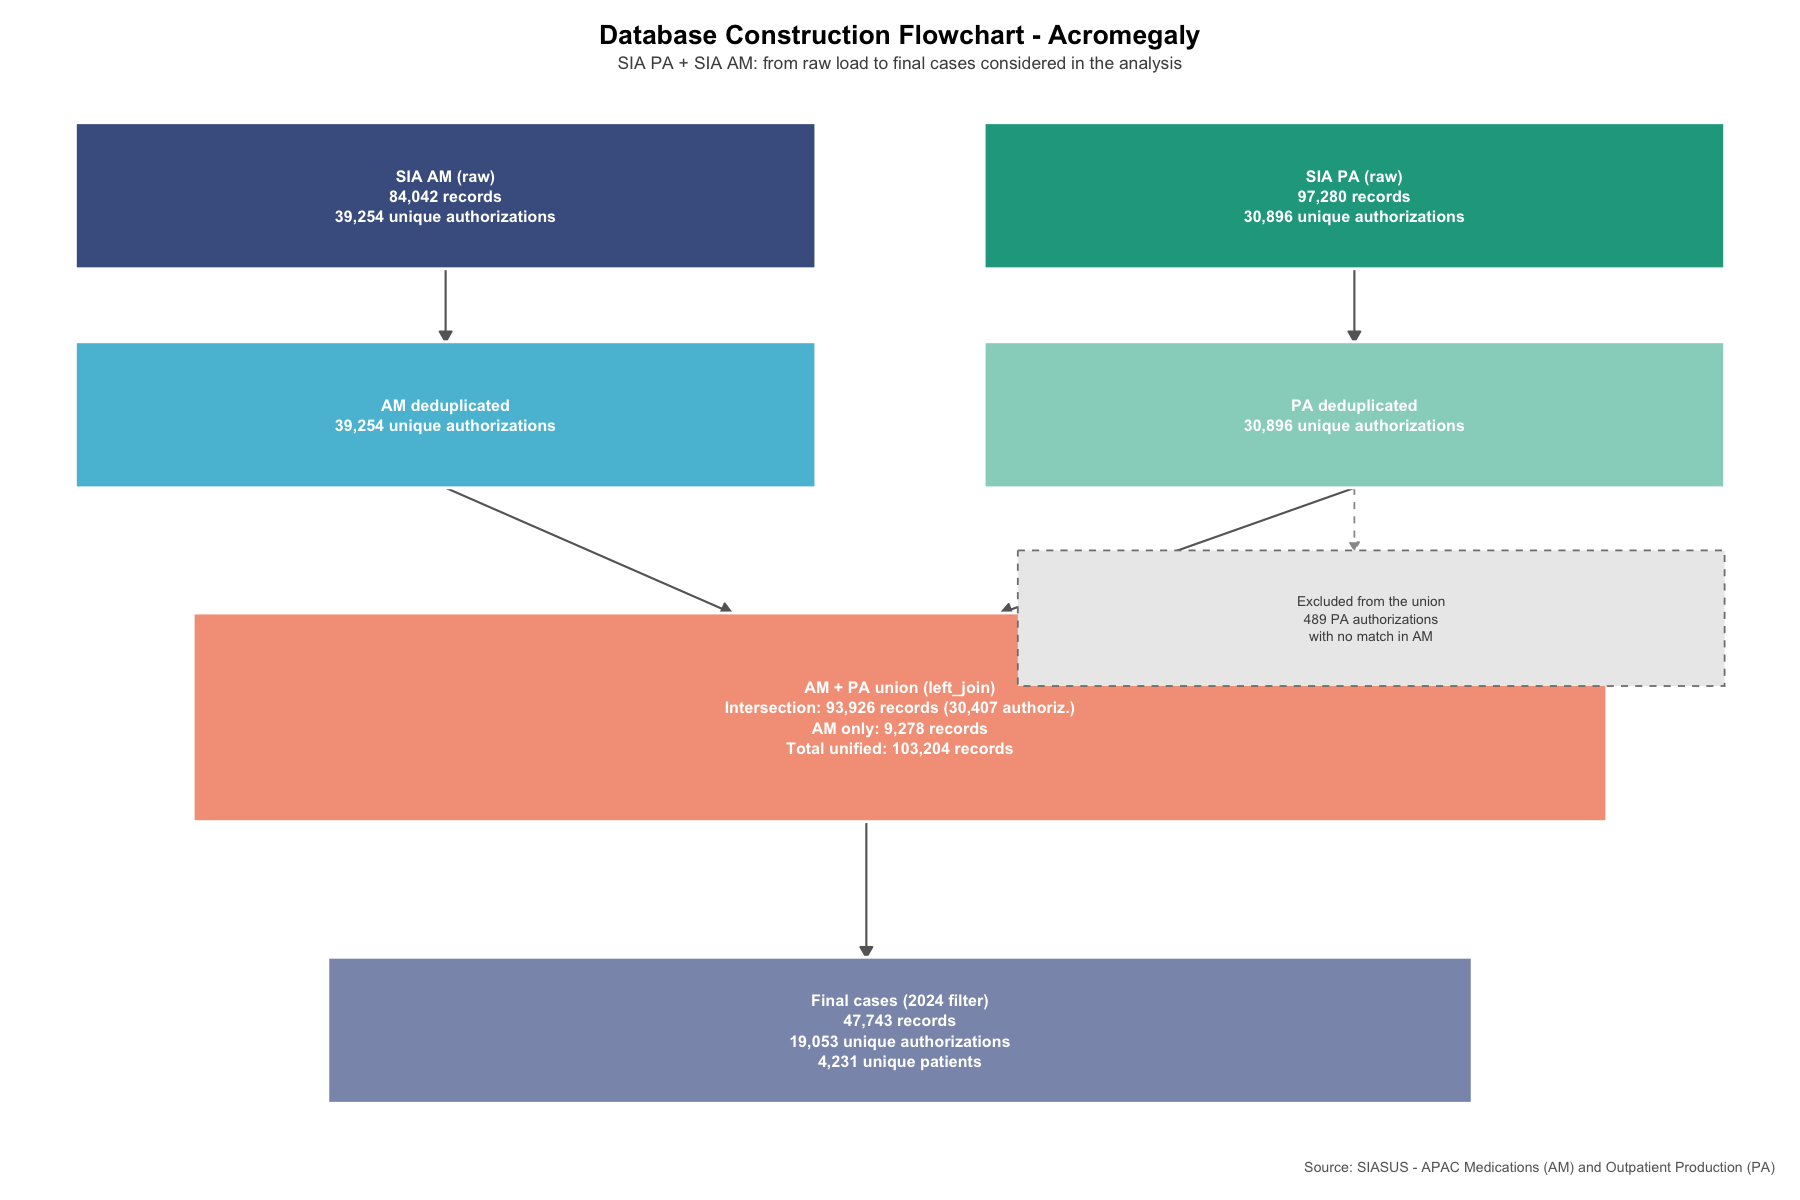

In [34]:
cat("=== 9. FLUXOGRAMA DE CONSTRUÇÃO DA BASE (SIA PA + SIA AM) ===\n")

library(ggplot2)

# Recalcula, a partir de data_am/data_pa (já carregados e padronizados nas
# seções 1 e 2, ainda sem o filtro de 2024), as contagens de cada etapa do
# pipeline de construção da base. Usa um nome de objeto próprio para não
# sobrescrever `dados_unificados`, que já está filtrado para 2024.
registros_am_brutos <- nrow(data_am)
autoriz_am_unicas <- n_distinct(data_am$AP_AUTORIZ, na.rm = TRUE)

registros_pa_brutos <- nrow(data_pa)
autoriz_pa_unicas <- n_distinct(data_pa$PA_AUTORIZ, na.rm = TRUE)

dados_unificados_full_fluxo <- data_am %>%
  left_join(data_pa, by = c(
    "AP_AUTORIZ" = "PA_AUTORIZ",
    "AP_CMP" = "PA_CMP",
    "AP_MVM" = "PA_MVM"
  ))

registros_uniao_total <- nrow(dados_unificados_full_fluxo)
registros_intersecao <- dados_unificados_full_fluxo %>% filter(!is.na(PA_PROC_ID)) %>% nrow()
registros_apenas_am <- dados_unificados_full_fluxo %>% filter(is.na(PA_PROC_ID)) %>% nrow()
autoriz_intersecao <- dados_unificados_full_fluxo %>% filter(!is.na(PA_PROC_ID)) %>% summarise(n_distinct(AP_AUTORIZ)) %>% pull()

# Autorizações que existem em PA mas nunca aparecem em AM - como a união
# parte de AM (left_join), esses casos não entram na base unificada
autoriz_pa_sem_correspondencia_am <- length(setdiff(
  unique(na.omit(data_pa$PA_AUTORIZ)),
  unique(na.omit(data_am$AP_AUTORIZ))
))

registros_finais <- nrow(dados_unificados)
autoriz_finais <- n_distinct(dados_unificados$AP_AUTORIZ, na.rm = TRUE)
pacientes_finais <- n_distinct(dados_unificados$AP_CNSPCN, na.rm = TRUE)

# --- Print do resumo no notebook ---
cat("\n📥 ETAPA 1 - Casos brutos carregados:\n")
cat("  • SIA AM:", format(registros_am_brutos, big.mark = ".", decimal.mark = ","), "registros |", format(autoriz_am_unicas, big.mark = ".", decimal.mark = ","), "autorizações únicas\n")
cat("  • SIA PA:", format(registros_pa_brutos, big.mark = ".", decimal.mark = ","), "registros |", format(autoriz_pa_unicas, big.mark = ".", decimal.mark = ","), "autorizações únicas\n")

cat("\n🧹 ETAPA 2 - Deduplicação (autorizações únicas por fonte):\n")
cat("  • AM:", format(autoriz_am_unicas, big.mark = ".", decimal.mark = ","), "autorizações\n")
cat("  • PA:", format(autoriz_pa_unicas, big.mark = ".", decimal.mark = ","), "autorizações\n")

cat("\n🔗 ETAPA 3 - União dos casos (left_join AM + PA por autorização/competência/movimentação):\n")
cat("  • Interseção (AM com correspondência em PA):", format(registros_intersecao, big.mark = ".", decimal.mark = ","), "registros |", format(autoriz_intersecao, big.mark = ".", decimal.mark = ","), "autorizações\n")
cat("  • Somente AM (sem correspondência em PA):", format(registros_apenas_am, big.mark = ".", decimal.mark = ","), "registros/autorizações\n")
cat("  • Total unificado:", format(registros_uniao_total, big.mark = ".", decimal.mark = ","), "registros\n")
cat("  • ⚠️ Autorizações exclusivas de PA sem correspondência em AM (não entram na união):", format(autoriz_pa_sem_correspondencia_am, big.mark = ".", decimal.mark = ","), "\n")

cat("\n✅ ETAPA 4 - Casos finais considerados (após filtro do ano de 2024):\n")
cat("  • Registros finais:", format(registros_finais, big.mark = ".", decimal.mark = ","), "\n")
cat("  • Autorizações únicas finais:", format(autoriz_finais, big.mark = ".", decimal.mark = ","), "\n")
cat("  • Pacientes únicos finais:", format(pacientes_finais, big.mark = ".", decimal.mark = ","), "\n")

# --- Tabela-resumo para exportação ---
tabela_fluxo <- tibble::tibble(
  etapa = c(
    "1. Casos brutos - SIA AM", "1. Casos brutos - SIA PA",
    "2. Deduplicação - autorizações únicas AM", "2. Deduplicação - autorizações únicas PA",
    "3. União - interseção AM x PA", "3. União - somente AM", "3. União - total unificado",
    "3. União - autorizações PA sem correspondência em AM (excluídas)",
    "4. Casos finais - registros (2024)", "4. Casos finais - autorizações únicas (2024)", "4. Casos finais - pacientes únicos (2024)"
  ),
  valor = c(
    registros_am_brutos, registros_pa_brutos,
    autoriz_am_unicas, autoriz_pa_unicas,
    registros_intersecao, registros_apenas_am, registros_uniao_total,
    autoriz_pa_sem_correspondencia_am,
    registros_finais, autoriz_finais, pacientes_finais
  )
)
print(tabela_fluxo)

write.xlsx(tabela_fluxo, gerar_nome_arquivo("fluxograma_uniao_dados"))
cat("\n✅ Tabela do fluxograma exportada para:", gerar_nome_arquivo("fluxograma_uniao_dados"), "\n")

# --- Building the flowchart (ggplot2: rectangles + arrows) - labels in English ---
format_num <- function(x) format(x, big.mark = ",", decimal.mark = ".", scientific = FALSE)

caixas <- tibble::tibble(
  id = c("am_bruto", "pa_bruto", "am_dedup", "pa_dedup", "uniao", "final"),
  xmin = c(0.3, 5.7, 0.3, 5.7, 1.0, 1.8),
  xmax = c(4.7, 10.1, 4.7, 10.1, 9.4, 8.6),
  ymin = c(8.6, 8.6, 6.5, 6.5, 3.3, 0.6),
  ymax = c(10.0, 10.0, 7.9, 7.9, 5.3, 2.0),
  fill = c("#3C5488", "#00A087", "#4DBBD5", "#91D1C2", "#F39B7F", "#8491B4"),
  label = c(
    paste0("SIA AM (raw)\n", format_num(registros_am_brutos), " records\n", format_num(autoriz_am_unicas), " unique authorizations"),
    paste0("SIA PA (raw)\n", format_num(registros_pa_brutos), " records\n", format_num(autoriz_pa_unicas), " unique authorizations"),
    paste0("AM deduplicated\n", format_num(autoriz_am_unicas), " unique authorizations"),
    paste0("PA deduplicated\n", format_num(autoriz_pa_unicas), " unique authorizations"),
    paste0("AM + PA union (left_join)\nIntersection: ", format_num(registros_intersecao), " records (", format_num(autoriz_intersecao), " authoriz.)\nAM only: ", format_num(registros_apenas_am), " records\nTotal unified: ", format_num(registros_uniao_total), " records"),
    paste0("Final cases (2024 filter)\n", format_num(registros_finais), " records\n", format_num(autoriz_finais), " unique authorizations\n", format_num(pacientes_finais), " unique patients")
  )
)

caixa_excluidos <- tibble::tibble(
  xmin = 5.9, xmax = 10.1, ymin = 4.6, ymax = 5.9,
  label = paste0("Excluded from the union\n", format_num(autoriz_pa_sem_correspondencia_am), " PA authorizations\nwith no match in AM")
)

setas <- tibble::tibble(
  x = c(2.5, 7.9, 2.5, 7.9, 5.0),
  xend = c(2.5, 7.9, 4.2, 5.8, 5.0),
  y = c(8.6, 8.6, 6.5, 6.5, 3.3),
  yend = c(7.9, 7.9, 5.3, 5.3, 2.0)
)

seta_excluidos <- tibble::tibble(x = 7.9, xend = 7.9, y = 6.5, yend = 5.9)

p_fluxo <- ggplot() +
  geom_segment(data = setas, aes(x = x, y = y, xend = xend, yend = yend),
               arrow = arrow(length = unit(0.25, "cm"), type = "closed"),
               color = "gray40", linewidth = 0.6) +
  geom_segment(data = seta_excluidos, aes(x = x, y = y, xend = xend, yend = yend),
               arrow = arrow(length = unit(0.2, "cm"), type = "closed"),
               color = "gray60", linewidth = 0.5, linetype = "dashed") +
  geom_rect(data = caixas, aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax, fill = fill),
            color = "white", linewidth = 0.8, alpha = 0.95) +
  geom_text(data = caixas, aes(x = (xmin + xmax) / 2, y = (ymin + ymax) / 2, label = label),
            color = "white", size = 3.4, fontface = "bold", lineheight = 1.05) +
  geom_rect(data = caixa_excluidos, aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax),
            fill = "grey92", color = "grey50", linewidth = 0.5, linetype = "dashed") +
  geom_text(data = caixa_excluidos, aes(x = (xmin + xmax) / 2, y = (ymin + ymax) / 2, label = label),
            color = "grey30", size = 2.9, lineheight = 1.05) +
  scale_fill_identity() +
  scale_x_continuous(limits = c(0, 10.4), expand = c(0, 0)) +
  scale_y_continuous(limits = c(0.2, 10.3), expand = c(0, 0)) +
  labs(
    title = "Database Construction Flowchart - Acromegaly",
    subtitle = "SIA PA + SIA AM: from raw load to final cases considered in the analysis",
    caption = "Source: SIASUS - APAC Medications (AM) and Outpatient Production (PA)"
  ) +
  theme_void(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold", size = 16, hjust = 0.5, margin = margin(b = 4)),
    plot.subtitle = element_text(size = 10.5, hjust = 0.5, margin = margin(b = 12), color = "grey30"),
    plot.caption = element_text(size = 8.5, hjust = 1, margin = margin(t = 10), color = "grey40"),
    plot.background = element_rect(fill = "white", color = NA),
    panel.background = element_rect(fill = "white", color = NA),
    plot.margin = margin(15, 15, 15, 15)
  )

print(p_fluxo)

cat("\n✅ FLUXOGRAMA CRIADO COM SUCESSO!\n")

# Salva SOMENTE como PNG (sem PDF), na pasta resultados/, com o padrao
# de nome AAAAMMDD_dados2024_indicador.png (mesmo padrao das demais figuras)
tryCatch({
  caminho_fluxo <- gerar_nome_png("fluxograma_uniao_dados")
  cat("\nSalvando fluxograma (PNG) em:", caminho_fluxo, "\n")

  ggsave(
    filename = caminho_fluxo,
    plot = p_fluxo,
    device = "png",
    width = 14,
    height = 10,
    units = "in",
    dpi = 300
  )

  if (file.exists(caminho_fluxo)) {
    cat("✅ Fluxograma salvo com sucesso em:", caminho_fluxo, "\n")
  } else {
    cat("❌ ggsave não sinalizou erro, mas o arquivo não foi encontrado em:", caminho_fluxo, "\n")
  }
}, error = function(e) {
  cat("❌ ERRO ao salvar o fluxograma:\n")
  print(e)
})

cat("\n--- FIM DO PROCESSO DE CRIAÇÃO DO FLUXOGRAMA ---\n")